In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Исследование причин падения оборота сервиса за последний месяц

## Загрузим данные и посмотрим на базовую информацию о них 

In [2]:
funnel = pd.read_csv('grocery_delivery_funnel_2025_11_2026_04.csv')
marketing = pd.read_csv('grocery_delivery_marketing_communications_2025_11_2026_04.csv')
orders = pd.read_csv('grocery_delivery_orders_2025_11_2026_04.csv')

print(f"orders shape = {orders.shape}, funnel shape = {funnel.shape}, marketing shape = {marketing.shape}")

orders shape = (21884, 21), funnel shape = (144710, 23), marketing shape = (72193, 10)


In [3]:
orders.head()

,order_id,session_id,client_id,address_id,store_id,city,platform,order_created_at,order_date,delivery_slot_start,...,gross_merchandise_value,discount_type,discount_amount,delivery_fee,service_fee,paid_amount,payment_method,campaign_id,experiment_group,is_marketing_touched
0,O000000112,SESS000000651,C008041,A0011675,S031,Новосибирск,ios,2025-11-01 09:00:00,2025-11-01,2025-11-01 18:00:00,...,2620.76,none,0.0,0,39.31,2660.07,cash,NaN,no_campaign,0
1,O000000026,SESS000000148,C002410,A0002250,S067,Москва,ios,2025-11-01 09:18:00,2025-11-01,2025-11-01 11:00:00,...,4767.18,none,0.0,99,71.51,4937.69,card,NaN,no_campaign,0
2,O000000169,SESS000000872,C006795,A0006500,S011,Москва,ios,2025-11-01 09:19:11,2025-11-01,2025-11-01 19:00:00,...,3112.03,none,0.0,99,0.00,3211.03,card,NaN,no_campaign,0
3,O000000072,SESS000000433,C008460,A0010616,S057,Москва,web,2025-11-01 09:27:00,2025-11-01,2025-11-01 20:00:00,...,3380.14,none,0.0,99,50.70,3529.84,card,NaN,no_campaign,0
4,O000000008,SESS000000058,C008434,A0001936,S026,Екатеринбург,ios,2025-11-01 09:31:13,2025-11-01,2025-11-01 22:00:00,...,3501.61,fixed_amount,200.0,99,0.00,3400.61,card,NaN,no_campaign,0


In [4]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21884 entries, 0 to 21883
Data columns (total 21 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   order_id                 21884 non-null  object 
 1   session_id               21884 non-null  object 
 2   client_id                21884 non-null  object 
 3   address_id               21884 non-null  object 
 4   store_id                 21884 non-null  object 
 5   city                     21884 non-null  object 
 6   platform                 21884 non-null  object 
 7   order_created_at         21884 non-null  object 
 8   order_date               21884 non-null  object 
 9   delivery_slot_start      21884 non-null  object 
 10  items_count              21884 non-null  int64  
 11  gross_merchandise_value  21884 non-null  float64
 12  discount_type            21884 non-null  object 
 13  discount_amount          21884 non-null  float64
 14  delivery_fee          

In [5]:
funnel.head()

,session_id,client_id,address_id,session_start_at,session_date,city,platform,traffic_source,campaign_id,experiment_group,...,product_card_view,add_to_cart,cart_visit,purchase,order_id,search_at,product_card_view_at,add_to_cart_at,cart_visit_at,purchase_at
0,SESS000000514,C003975,A0000378,2025-11-01 08:04:53,2025-11-01,Москва,android,direct,NaN,no_campaign,...,1,0,0,0,NaN,2025-11-01 08:07:53,2025-11-01 08:07:53,NaN,NaN,NaN
1,SESS000000286,C000830,A0011473,2025-11-01 08:11:12,2025-11-01,Москва,android,organic,NaN,no_campaign,...,1,1,0,0,NaN,2025-11-01 08:12:12,2025-11-01 08:16:12,2025-11-01 08:23:12,NaN,NaN
2,SESS000000248,C005196,A0005849,2025-11-01 08:11:57,2025-11-01,Казань,ios,organic,NaN,no_campaign,...,1,1,1,0,NaN,2025-11-01 08:15:57,2025-11-01 08:21:57,2025-11-01 08:21:57,2025-11-01 08:31:57,NaN
3,SESS000000387,C007786,A0001717,2025-11-01 08:16:26,2025-11-01,Москва,android,direct,NaN,no_campaign,...,1,0,0,0,NaN,2025-11-01 08:18:26,2025-11-01 08:24:26,NaN,NaN,NaN
4,SESS000000197,C001541,A0001204,2025-11-01 08:21:22,2025-11-01,Санкт-Петербург,web,crm,CMP0001,test,...,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN


In [6]:
funnel.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144710 entries, 0 to 144709
Data columns (total 23 columns):
 #   Column                Non-Null Count   Dtype 
---  ------                --------------   ----- 
 0   session_id            144710 non-null  object
 1   client_id             144710 non-null  object
 2   address_id            144710 non-null  object
 3   session_start_at      144710 non-null  object
 4   session_date          144710 non-null  object
 5   city                  144710 non-null  object
 6   platform              144710 non-null  object
 7   traffic_source        144710 non-null  object
 8   campaign_id           6699 non-null    object
 9   experiment_group      144710 non-null  object
 10  timing_period         144710 non-null  object
 11  service_visit         144710 non-null  int64 
 12  product_search        144710 non-null  int64 
 13  product_card_view     144710 non-null  int64 
 14  add_to_cart           144710 non-null  int64 
 15  cart_visit       

In [7]:
marketing.head()

,communication_id,campaign_id,communication_type,client_id,send_datetime,send_date,send_hour,timing_period,experiment_group,send_status
0,COM00000001,CMP0001,email,C000437,2025-11-01 18:15:00,2025-11-01,18,evening,control,holdout_control
1,COM00000002,CMP0001,email,C004047,2025-11-01 18:15:00,2025-11-01,18,evening,control,holdout_control
2,COM00000003,CMP0001,email,C003127,2025-11-01 18:15:00,2025-11-01,18,evening,test,sent
3,COM00000004,CMP0001,email,C005987,2025-11-01 18:15:00,2025-11-01,18,evening,test,sent
4,COM00000005,CMP0001,email,C002831,2025-11-01 18:15:00,2025-11-01,18,evening,test,sent


In [8]:
marketing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72193 entries, 0 to 72192
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype 
---  ------              --------------  ----- 
 0   communication_id    72193 non-null  object
 1   campaign_id         72193 non-null  object
 2   communication_type  72193 non-null  object
 3   client_id           72193 non-null  object
 4   send_datetime       72193 non-null  object
 5   send_date           72193 non-null  object
 6   send_hour           72193 non-null  int64 
 7   timing_period       72193 non-null  object
 8   experiment_group    72193 non-null  object
 9   send_status         72193 non-null  object
dtypes: int64(1), object(9)
memory usage: 5.5+ MB


**Преобразуем поля с датой и временем в нужный формат и добавим поле месяца для дальнейшего анализа**

In [9]:
for col in ['order_created_at', 'order_date', 'delivery_slot_start']:
    orders[col] = pd.to_datetime(orders[col], errors='coerce')

for col in ['session_start_at', 'session_date', 'search_at', 'product_card_view_at',
    'add_to_cart_at', 'cart_visit_at', 'purchase_at']:
    funnel[col] = pd.to_datetime(funnel[col], errors='coerce')

for col in ['send_datetime', 'send_date']:
    marketing[col] = pd.to_datetime(marketing[col], errors='coerce')  

In [10]:
orders['month'] = orders['order_date'].dt.to_period('M').astype(str)
funnel['month'] = funnel['session_date'].dt.to_period('M').astype(str)
marketing['month'] = marketing['send_date'].dt.to_period('M').astype(str)

**Посмотрим на описательные статистики**

In [11]:
orders.describe()

,order_created_at,order_date,delivery_slot_start,items_count,gross_merchandise_value,discount_amount,delivery_fee,service_fee,paid_amount,is_marketing_touched
count,21884,21884,21884,21884.000000,21884.000000,21884.000000,21884.000000,21884.000000,21884.000000,21884.000000
mean,2026-01-29 00:38:56.904907520,2026-01-28 07:41:08.214220544,2026-01-28 23:40:54.066898432,9.754250,2822.223200,49.196609,104.753838,35.940552,2913.720966,0.047797
min,2025-11-01 09:00:00,2025-11-01 00:00:00,2025-11-01 10:00:00,1.000000,550.000000,0.000000,0.000000,0.000000,456.080000,0.000000
25%,2025-12-15 19:25:17.249999872,2025-12-15 00:00:00,2025-12-15 19:00:00,7.000000,2066.570000,0.000000,99.000000,10.810000,2144.270000,0.000000
50%,2026-01-28 23:02:34,2026-01-28 00:00:00,2026-01-28 22:00:00,10.000000,2683.220000,0.000000,99.000000,37.770000,2771.580000,0.000000
75%,2026-03-13 19:42:05.750000128,2026-03-13 00:00:00,2026-03-13 19:00:00,12.000000,3429.850000,0.000000,149.000000,53.250000,3534.017500,0.000000
max,2026-04-30 23:45:19,2026-04-30 00:00:00,2026-04-30 22:00:00,26.000000,9046.220000,882.710000,199.000000,157.520000,9195.220000,1.000000
std,NaN,NaN,NaN,3.286488,1049.980977,108.654131,66.524086,26.608279,1062.026662,0.213342


In [12]:
orders.describe(include = [object])

,order_id,session_id,client_id,address_id,store_id,city,platform,discount_type,payment_method,campaign_id,experiment_group,month
count,21884,21884,21884,21884,21884,21884,21884,21884,21884,1046,21884,21884
unique,21884,21884,7244,5720,80,5,3,4,3,61,3,6
top,O000000112,SESS000000651,C004689,A0003482,S067,Москва,ios,none,card,CMP0043,no_campaign,2026-03
freq,1,1,19,25,325,11520,9363,16338,16701,31,20838,3955


In [13]:
funnel.describe()

,session_start_at,session_date,service_visit,product_search,product_card_view,add_to_cart,cart_visit,purchase,search_at,product_card_view_at,add_to_cart_at,cart_visit_at,purchase_at
count,144710,144710,144710.0,144710.000000,144710.000000,144710.000000,144710.000000,144710.000000,104124,86761,44978,35223,21884
mean,2026-01-30 05:44:54.518008576,2026-01-29 13:11:55.522078464,1.0,0.719536,0.599551,0.310815,0.243404,0.151227,2026-01-30 03:36:08.781827328,2026-01-30 03:28:58.497319936,2026-01-28 17:47:19.710947584,2026-01-28 20:38:24.868750848,2026-01-29 00:38:25.928851968
min,2025-11-01 08:04:53,2025-11-01 00:00:00,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,2025-11-01 08:07:53,2025-11-01 08:07:53,2025-11-01 08:21:57,2025-11-01 08:31:57,2025-11-01 08:55:00
25%,2025-12-15 19:21:42.249999872,2025-12-15 00:00:00,1.0,0.000000,0.000000,0.000000,0.000000,0.000000,2025-12-15 21:25:26.249999872,2025-12-15 23:32:42,2025-12-15 08:16:42.500000,2025-12-15 13:03:26,2025-12-15 19:19:36
50%,2026-01-30 14:37:29,2026-01-30 00:00:00,1.0,1.000000,1.000000,0.000000,0.000000,0.000000,2026-01-30 11:36:35.500000,2026-01-30 11:11:08,2026-01-28 18:44:05,2026-01-28 19:36:27,2026-01-28 23:08:15.500000
75%,2026-03-15 22:52:33.750000128,2026-03-15 00:00:00,1.0,1.000000,1.000000,1.000000,0.000000,0.000000,2026-03-15 19:40:18,2026-03-15 18:46:13,2026-03-13 16:02:06.500000,2026-03-13 18:28:42,2026-03-13 19:50:16
max,2026-04-30 23:55:31,2026-04-30 00:00:00,1.0,1.000000,1.000000,1.000000,1.000000,1.000000,2026-04-30 23:58:26,2026-04-30 23:58:31,2026-04-30 23:42:25,2026-04-30 23:34:35,2026-04-30 23:46:19
std,NaN,NaN,0.0,0.449228,0.489991,0.462829,0.429138,0.358271,NaN,NaN,NaN,NaN,NaN


In [14]:
funnel.describe(include = [object])

,session_id,client_id,address_id,city,platform,traffic_source,campaign_id,experiment_group,timing_period,order_id,month
count,144710,144710,144710,144710,144710,144710,6699,144710,144710,21884,144710
unique,144710,8491,6451,5,3,5,61,3,3,21884,6
top,SESS000000514,C007188,A0010504,Москва,ios,direct,CMP0050,no_campaign,no_campaign,O000000112,2025-12
freq,1,99,142,76452,61600,49210,177,138011,138011,1,25678


In [15]:
marketing.describe()

,send_datetime,send_date,send_hour
count,72193,72193,72193.000000
mean,2026-01-30 20:07:07.042788096,2026-01-30 03:05:58.887981056,16.620143
min,2025-11-01 18:15:00,2025-11-01 00:00:00,6.000000
25%,2025-12-16 20:45:00,2025-12-16 00:00:00,17.000000
50%,2026-01-30 19:30:00,2026-01-30 00:00:00,18.000000
75%,2026-03-16 18:45:00,2026-03-16 00:00:00,19.000000
max,2026-04-30 07:30:00,2026-04-30 00:00:00,20.000000
std,NaN,NaN,4.338967


In [16]:
marketing.describe(include = [object])

,communication_id,campaign_id,communication_type,client_id,timing_period,experiment_group,send_status,month
count,72193,72193,72193,72193,72193,72193,72193,72193
unique,72193,61,3,8499,2,2,2,6
top,COM00000001,CMP0010,push,C002232,evening,control,holdout_control,2026-03
freq,1,1489,41851,20,60476,36242,36242,13208


In [17]:
for col in ['city', 'platform', 'discount_type', 'payment_method']:
    print(f'\n{col}:')
    print('Уникальных значений:', orders[col].nunique())
    print(orders[col].value_counts(dropna=False))


city:
Уникальных значений: 5
city
Москва             11520
Санкт-Петербург     4889
Казань              2110
Новосибирск         1768
Екатеринбург        1597
Name: count, dtype: int64

platform:
Уникальных значений: 3
platform
ios        9363
android    9201
web        3320
Name: count, dtype: int64

discount_type:
Уникальных значений: 4
discount_type
none             16338
percent           2452
fixed_amount      2175
free_delivery      919
Name: count, dtype: int64

payment_method:
Уникальных значений: 3
payment_method
card    16701
sbp      3867
cash     1316
Name: count, dtype: int64


In [18]:
for col in ['city', 'platform', 'traffic_source', 'timing_period']:
    print(f'\n{col}:')
    print('Уникальных значений:', funnel[col].nunique())
    print(funnel[col].value_counts(dropna=False))


city:
Уникальных значений: 5
city
Москва             76452
Санкт-Петербург    31746
Казань             14208
Новосибирск        11591
Екатеринбург       10713
Name: count, dtype: int64

platform:
Уникальных значений: 3
platform
ios        61600
android    61444
web        21666
Name: count, dtype: int64

traffic_source:
Уникальных значений: 5
traffic_source
direct      49210
organic     34951
crm         28873
paid        22948
referral     8728
Name: count, dtype: int64

timing_period:
Уникальных значений: 3
timing_period
no_campaign      138011
evening            5638
early_morning      1061
Name: count, dtype: int64


In [19]:
for col in ['communication_type', 'timing_period', 'send_status']:
    print(f'\n{col}:')
    print('Уникальных значений:', marketing[col].nunique())
    print(marketing[col].value_counts(dropna=False))


communication_type:
Уникальных значений: 3
communication_type
push      41851
email     25668
in_app     4674
Name: count, dtype: int64

timing_period:
Уникальных значений: 2
timing_period
evening          60476
early_morning    11717
Name: count, dtype: int64

send_status:
Уникальных значений: 2
send_status
holdout_control    36242
sent               35951
Name: count, dtype: int64


**Проверим данные на корректность**

Дубликаты, пропуски в ключевых идентификаторах и нарушения связей между таблицами отсутствуют. Также не обнаружено аномальных значений в денежных показателях и количестве товаров в заказе.

In [20]:
quality = {
    # Проверка уникальности заказов: один заказ должен иметь уникальный order_id
    'duplicate_order_id': orders['order_id'].duplicated().sum(),

    # Проверка уникальности сессий: одна строка в funnel соответствует одной пользовательской сессии
    'duplicate_session_id_funnel': funnel['session_id'].duplicated().sum(),

    # Проверка связности таблиц: все заказы должны быть привязаны к существующей сессии из воронки
    'orders_without_session': (
        ~orders['session_id'].isin(funnel['session_id'])
    ).sum(),

    # Проверка логики покупки: если в сессии зафиксирована покупка (purchase = 1), то должен существовать соответствующий order_id
    'purchase_sessions_without_order_id': (
        (funnel['purchase'] == 1) &
        (funnel['order_id'].isna())
    ).sum(),
    
    # Заказы без order_id
    'orders_missing_order_id': orders['order_id'].isna().sum(),

    # Сессии без session_id
    'funnel_missing_session_id': funnel['session_id'].isna().sum(),

    # Покупка = 0, но order_id заполнен
    'non_purchase_sessions_with_order_id': ((funnel['purchase'] == 0) & (funnel['order_id'].notna())).sum(),

    # order_id из воронки отсутствуют в заказах
    'funnel_order_id_not_in_orders': (
        funnel.loc[funnel['order_id'].notna(), 'order_id']
        .isin(orders['order_id'])
        .eq(False)
        .sum()
    ),

    # Заказы с отрицательными или нулевыми суммами
    'orders_non_positive_gmv': (orders['gross_merchandise_value'] <= 0).sum(),
    'orders_negative_paid_amount': (orders['paid_amount'] < 0).sum(),

    # Отрицательные скидки / комиссии / доставка
    'orders_negative_discount': (orders['discount_amount'] < 0).sum(),
    'orders_negative_delivery_fee': (orders['delivery_fee'] < 0).sum(),
    'orders_negative_service_fee': (orders['service_fee'] < 0).sum(),

    # Количество товаров <= 0
    'orders_non_positive_items_count': (orders['items_count'] <= 0).sum(),

    # Заказ без клиента
    'orders_missing_client_id': orders['client_id'].isna().sum(),

    # Сессия без клиента
    'funnel_missing_client_id': funnel['client_id'].isna().sum(),
}


for k, v in quality.items():
    print(f'{k}: {v}')

duplicate_order_id: 0
duplicate_session_id_funnel: 0
orders_without_session: 0
purchase_sessions_without_order_id: 0
orders_missing_order_id: 0
funnel_missing_session_id: 0
non_purchase_sessions_with_order_id: 0
funnel_order_id_not_in_orders: 0
orders_non_positive_gmv: 0
orders_negative_paid_amount: 0
orders_negative_discount: 0
orders_negative_delivery_fee: 0
orders_negative_service_fee: 0
orders_non_positive_items_count: 0
orders_missing_client_id: 0
funnel_missing_client_id: 0


## Декомпозируем GMV и посмотрим на основные метрики в динамике и в различных срезах

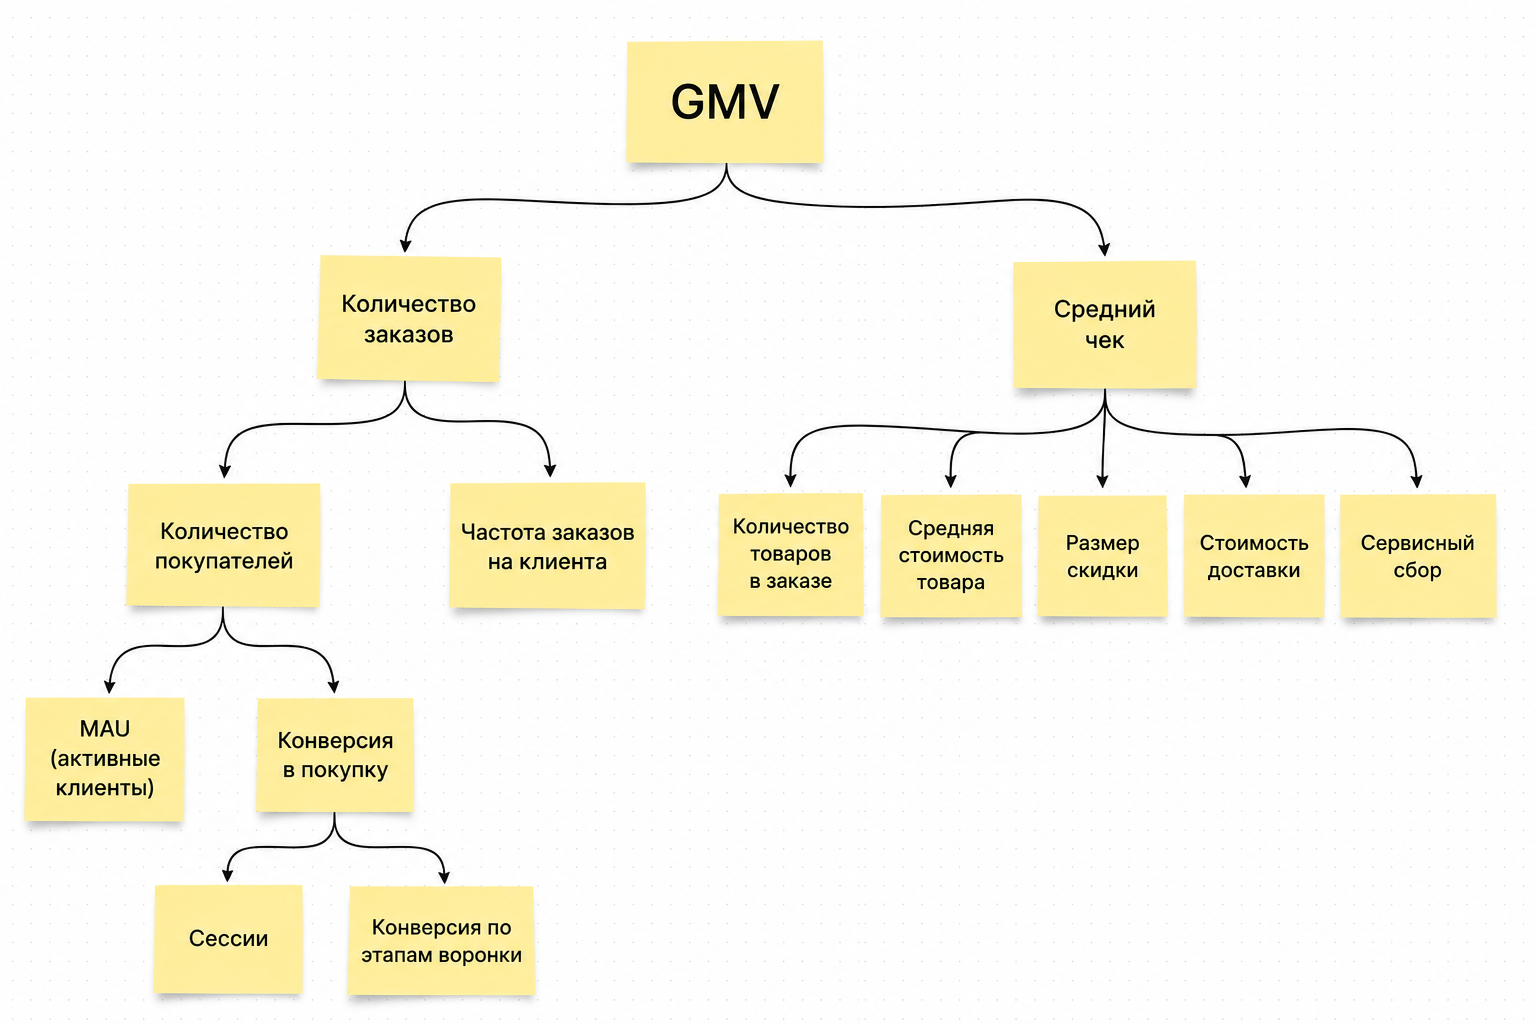

In [21]:
from IPython.display import Image, display

display(Image("gmv_tree.png"))

In [22]:
monthly_orders = orders.groupby('month').agg(
    gmv=('gross_merchandise_value', 'sum'), 
    paid=('paid_amount', 'sum'), 
    buyers=('client_id', 'nunique'),
    orders=('order_id', 'nunique'),
    aov_gmv=('gross_merchandise_value', 'mean'),
    items_per_order=('items_count', 'mean'),
    discount_sum=('discount_amount', 'sum'),
    discount_per_order=('discount_amount', 'mean'),
    avg_delivery_fee=('delivery_fee', 'mean'),
    avg_service_fee=('service_fee', 'mean'),
    marketing_touched_orders=('is_marketing_touched', 'sum')
).reset_index()

monthly_orders['orders_per_buyer'] = monthly_orders['orders'] / monthly_orders['buyers']

monthly_funnel = funnel.groupby('month').agg(
    funnel_clients=('client_id', 'nunique'),
    visits=('service_visit', 'sum'),
    sessions=('session_id', 'nunique'),
    searches=('product_search', 'sum'),
    card_views=('product_card_view', 'sum'),
    add_to_cart=('add_to_cart', 'sum'),
    cart_visits=('cart_visit', 'sum'),
    purchases=('purchase', 'sum')
).reset_index()

for step in ['searches', 'card_views', 'add_to_cart', 'cart_visits', 'purchases']:
    monthly_funnel[f'{step}_rate'] = monthly_funnel[step] / monthly_funnel['visits']

monthly_funnel['visit_to_search_cr'] = monthly_funnel['searches'] / monthly_funnel['sessions']
monthly_funnel['search_to_card_cr'] = monthly_funnel['card_views'] / monthly_funnel['searches']
monthly_funnel['card_to_cart_cr'] = monthly_funnel['add_to_cart'] / monthly_funnel['card_views']
monthly_funnel['cart_add_to_cart_visit_cr'] = monthly_funnel['cart_visits'] / monthly_funnel['add_to_cart']
monthly_funnel['cart_to_purchase_cr'] = monthly_funnel['purchases'] / monthly_funnel['cart_visits']
monthly_funnel['session_to_purchase_cr'] = monthly_funnel['purchases'] / monthly_funnel['sessions']


monthly = monthly_funnel.merge(monthly_orders, on='month')
monthly['order_conversion'] = monthly['orders'] / monthly['sessions']
monthly['gmv_per_session'] = monthly['gmv'] / monthly['sessions']
monthly['discount_share_gmv'] = monthly['discount_sum'] / monthly['gmv']
monthly['marketing_touched_share'] = monthly['marketing_touched_orders'] / monthly['orders']
monthly['paid_per_order'] = monthly['paid'] / monthly['orders']
monthly['avg_item_price'] = (monthly['gmv'] / (monthly['items_per_order'] * monthly['orders']))

- gmv — оборот, целевая метрика.

- paid — фактически оплаченная клиентами сумма. Нужна, чтобы отличать падение оборота от эффекта скидок, доставки и сервисных сборов.

- buyers — количество уникальных покупателей за месяц. Показывает, снижается ли количество клиентов, которые реально делают заказы.

- orders — количество заказов за месяц. Один из двух ключевых составляющих GMV.

- aov_gmv — средний чек за месяц. Вторая ключевая составляющая GMV.

- items_per_order — среднее количество товаров в заказе. Нужна, чтобы понять, не стал ли заказ меньше по наполнению.

- discount_sum — суммарный объем скидок. Помогает оценить, как менялась промо-активность и могла ли она влиять на paid_amount.

- discount_per_order — средняя скидка на заказ. Показывает, не изменился ли размер стимула к покупке.

- avg_delivery_fee — средняя стоимость доставки. Может влиять на решение пользователя завершить заказ.

- avg_service_fee — средний сервисный сбор. Также может влиять на конверсию в покупку и итоговую оплату.

- marketing_touched_orders — количество заказов, связанных с маркетинговыми коммуникациями. Нужно, чтобы понять, не связано ли падение заказов с изменением маркетингового воздействия.

- orders_per_buyer — среднее количество заказов на одного покупателя. Показывает частоту покупок: клиенты стали покупать реже или нет.

- funnel_clients — количество уникальных клиентов, попавших в воронку. Показывает охват аудитории на уровне сессий.

- visits — количество визитов в сервис. Верхний уровень воронки: отражает объем входящего пользовательского трафика.

- sessions — количество уникальных сессий. База для расчета конверсии из сессии в покупку.

- searches — количество сессий, где был поиск товара. Показывает вовлеченность пользователей после входа в сервис.

- card_views — количество сессий с просмотром карточки товара. Показывает, доходят ли пользователи до выбора конкретного товара.

- add_to_cart — количество сессий с добавлением товара в корзину. Шаг, отражающий намерение купить.

- cart_visits — количество сессий с переходом в корзину. Показывает, доходят ли пользователи до оформления заказа.

- purchases — количество сессий с покупкой. Финальный шаг воронки.

- searches_rate, card_views_rate, add_to_cart_rate, cart_visits_rate, purchases_rate — доля визитов, дошедших до каждого этапа. Нужны для общей оценки просадки воронки относительно верхнего уровня.

- visit_to_search_cr — конверсия из сессии в поиск. Показывает, насколько пользователи начинают искать товары после входа.

- search_to_card_cr — конверсия из поиска в просмотр карточки. Помогает найти проблемы с поисковой выдачей или релевантностью товаров.

- card_to_cart_cr — конверсия из карточки товара в добавление в корзину. Метрика качества карточки, цены, наличия товара и привлекательности предложения.

- cart_add_to_cart_visit_cr — конверсия из добавления в корзину в переход в корзину. Показывает, доходят ли пользователи от выбора товаров до корзины.

- cart_to_purchase_cr — конверсия из корзины в покупку. Показывает проблемы на этапе оформления: доставка, сборы, оплата.

- session_to_purchase_cr — итоговая конверсия из сессии в покупку. 

- order_conversion — отношение заказов к сессиям. Дублирует session_to_purchase_cr, но считается через таблицу заказов; полезно для сверки воронки и заказов.

- gmv_per_session — GMV на одну сессию. Показывает, сколько оборота приносит один визит.

- discount_share_gmv — доля скидок в обороте. Используется для оценки влияния промоактивности на динамику заказов и оборота.

- marketing_touched_share — доля заказов, совершенных после маркетингового воздействия. Используется для оценки вклада маркетинга в общий объем заказов и поиска возможной связи между маркетинговой активностью и падением оборота.

- paid_per_order — средняя сумма оплаты за заказ после применения скидок. Используется для анализа влияния скидок на выручку сервиса.

- avg_item_price — средняя стоимость одного товара. Используется для декомпозиции среднего чека и позволяет определить, связано ли его изменение с количеством товаров в заказе или с изменением стоимости товаров.

### Динамика основных метрик

В апреле наблюдается резкое снижение как GMV, так и фактически оплаченной суммы. Динамика этих двух метрик совпадает, поэтому падение нельзя объяснить только изменением скидок или комиссий. Необходимо разложить GMV на количество заказов и средний чек.

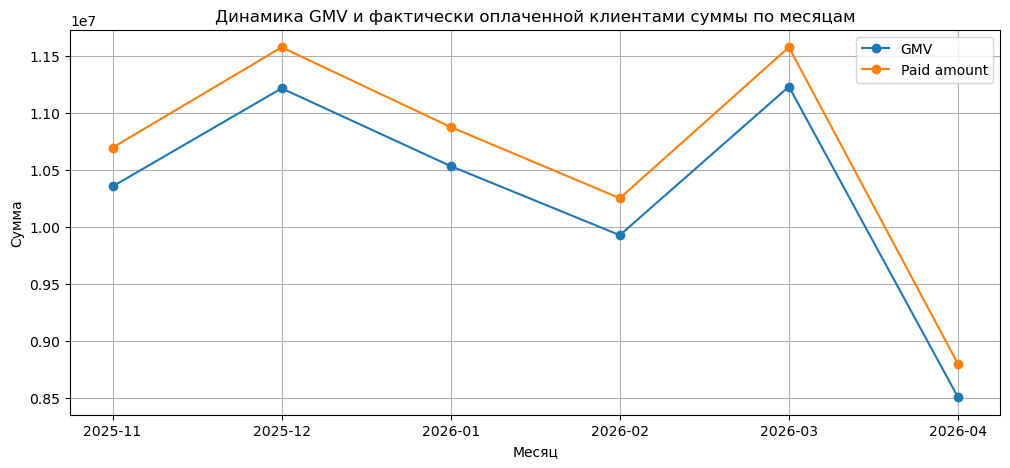

In [23]:
plt.figure(figsize=(12, 5))
plt.plot(monthly['month'], monthly['gmv'], marker='o', label='GMV')
plt.plot(monthly['month'], monthly['paid'], marker='o', label='Paid amount')
plt.title('Динамика GMV и фактически оплаченной клиентами суммы по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Сумма')
plt.legend()
plt.grid(True)
plt.show()

In [24]:
pd.set_option('display.max_columns', None)

key_cols = [
    'gmv', 'orders', 'buyers', 'orders_per_buyer', 'aov_gmv',
    'items_per_order', 'avg_item_price', 'sessions', 'session_to_purchase_cr', 'gmv_per_session'
]

monthly_changes = monthly[['month'] + key_cols].copy()

for col in key_cols:
    monthly_changes[col + '_mom_%'] = monthly_changes[col].pct_change() * 100

monthly_changes

,month,gmv,orders,buyers,orders_per_buyer,aov_gmv,items_per_order,avg_item_price,sessions,session_to_purchase_cr,gmv_per_session,gmv_mom_%,orders_mom_%,buyers_mom_%,orders_per_buyer_mom_%,aov_gmv_mom_%,items_per_order_mom_%,avg_item_price_mom_%,sessions_mom_%,session_to_purchase_cr_mom_%,gmv_per_session_mom_%
0,2025-11,10353931.61,3659,2812,1.301209,2829.716209,9.805138,288.595245,23910,0.153032,433.037708,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2025-12,11213674.63,3942,2959,1.332207,2844.666319,9.754186,291.635448,25678,0.153517,436.703584,8.303542,7.734354,5.227596,2.382225,0.528325,-0.519649,1.053449,7.394396,0.316551,0.846549
2,2026-01,10532168.55,3719,2871,1.295367,2831.989392,9.679215,292.584620,24135,0.154092,436.385687,-6.077455,-5.657027,-2.973978,-2.765288,-0.445638,-0.768602,0.325465,-6.009035,0.374513,-0.072795
3,2026-02,9926552.57,3491,2707,1.289620,2843.469656,9.721856,292.482176,22740,0.153518,436.523860,-5.750155,-6.130680,-5.712295,-0.443732,0.405378,0.440546,-0.035013,-5.779988,-0.372206,0.031663
4,2026-03,11228694.03,3955,2996,1.320093,2839.113535,9.748420,291.238336,25014,0.158111,448.896379,13.117761,13.291321,10.676025,2.363019,-0.153197,0.273235,-0.425270,10.000000,2.992110,2.834328
5,2026-04,8506511.12,3118,2525,1.234851,2728.194715,9.827774,277.600467,23233,0.134206,366.139161,-24.243095,-21.163085,-15.720961,-6.457268,-3.906812,0.814024,-4.682717,-7.120013,-15.119589,-18.435706


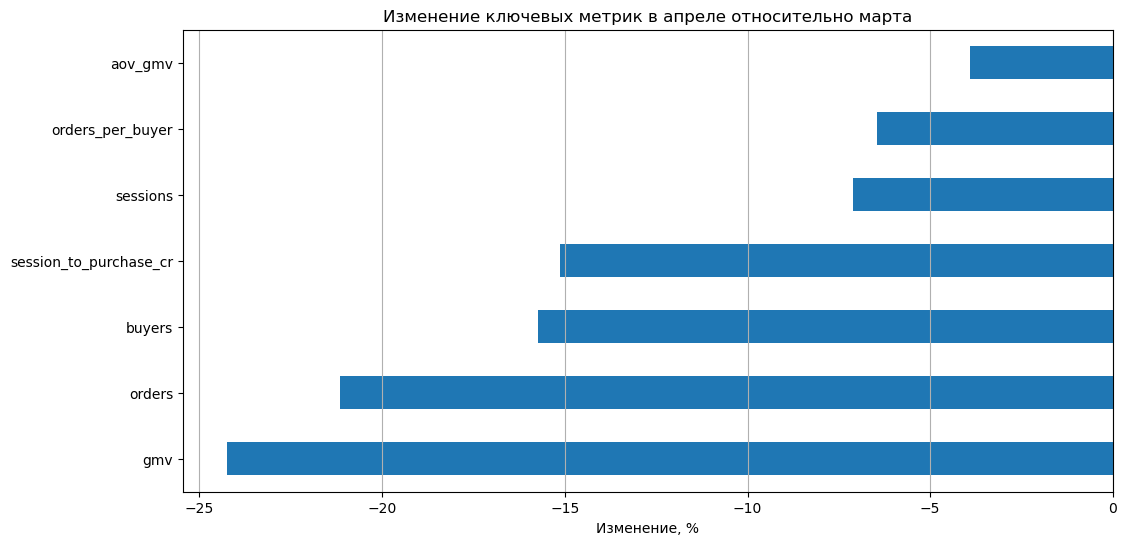

In [25]:
change_cols = [
    'gmv', 'orders', 'buyers', 'orders_per_buyer',
    'aov_gmv', 'sessions', 'session_to_purchase_cr'
]

change_apr = {}

for col in change_cols:
    march_value = monthly.loc[monthly['month'] == '2026-03', col].iloc[0]
    april_value = monthly.loc[monthly['month'] == '2026-04', col].iloc[0]
    change_apr[col] = (april_value / march_value - 1) * 100

change_apr = pd.Series(change_apr).sort_values()

plt.figure(figsize=(12, 6))
change_apr.plot(kind='barh')
plt.title('Изменение ключевых метрик в апреле относительно марта')
plt.xlabel('Изменение, %')
plt.grid(axis='x')
plt.show()

- GMV в апреле по сравнению с мартом упал на 24.2%.
- Количество заказов снизилось на 21.2%.
- Количество покупателей снизилось на 15.7%.
- Конверсия из сессии в покупку снизилась на 15.1%.
- Сессии снизились на 7.1%.
- Частота заказов на покупателя снизилась на 6.5%.
- Средний чек снизился на 3.9%.

Индексная динамика показывает, что GMV в большей степени повторяет динамику количества заказов, чем среднего чека. В апреле снижаются обе составляющие, однако основной вклад в падение оборота вносит снижение количества заказов.

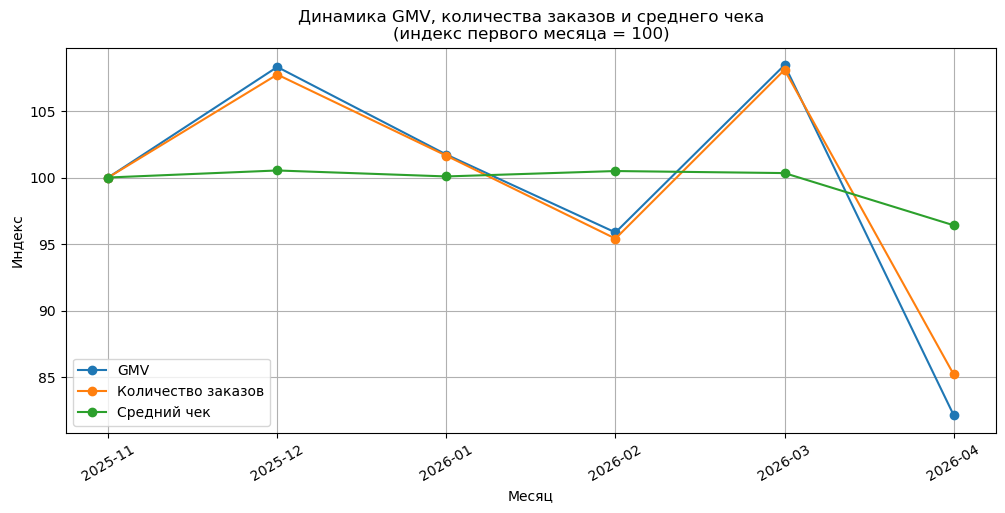

In [26]:
metrics = ['gmv', 'orders', 'aov_gmv']

index_df = monthly[['month'] + metrics].copy()

for col in metrics:
    index_df[col] = index_df[col] / index_df[col].iloc[0] * 100

plt.figure(figsize=(12, 5))

plt.plot(index_df['month'], index_df['gmv'], marker='o', label='GMV')
plt.plot(index_df['month'], index_df['orders'], marker='o', label='Количество заказов')
plt.plot(index_df['month'], index_df['aov_gmv'], marker='o', label='Средний чек')

plt.title('Динамика GMV, количества заказов и среднего чека\n(индекс первого месяца = 100)')
plt.xlabel('Месяц')
plt.ylabel('Индекс')
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)

plt.show()

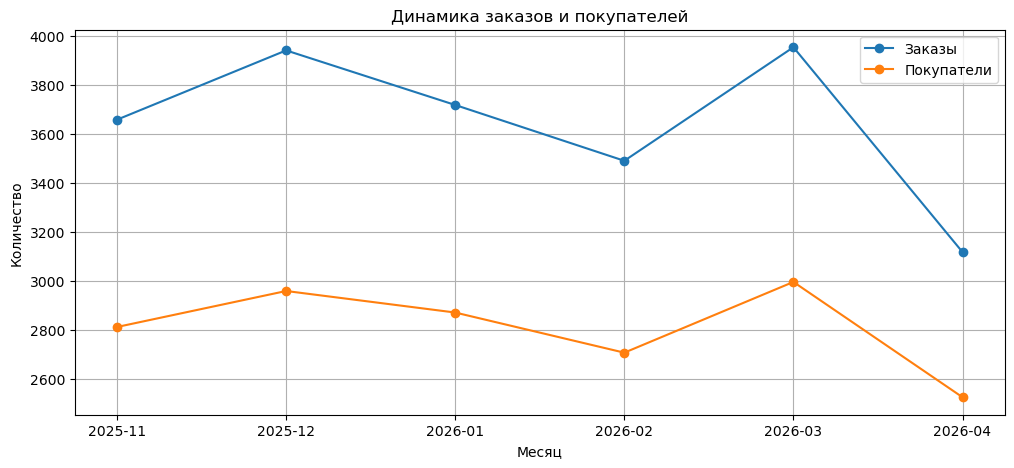

In [27]:
plt.figure(figsize=(12, 5))
#plt.plot(monthly['month'], monthly['sessions'], marker='o', label='Сессии')
plt.plot(monthly['month'], monthly['orders'], marker='o', label='Заказы')
plt.plot(monthly['month'], monthly['buyers'], marker='o', label='Покупатели')
plt.title('Динамика заказов и покупателей')
plt.xlabel('Месяц')
plt.ylabel('Количество')
plt.legend()
plt.grid(True)
plt.show()

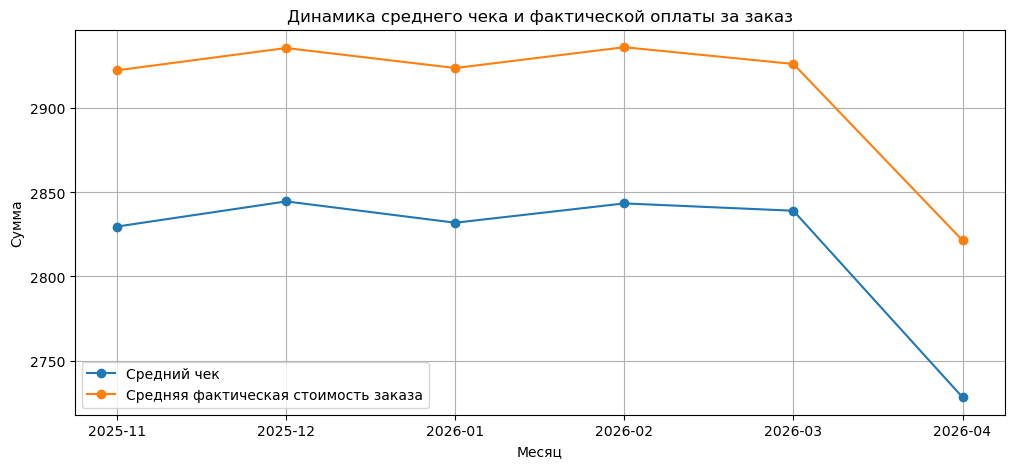

In [28]:
plt.figure(figsize=(12, 5))
plt.plot(monthly['month'], monthly['aov_gmv'], marker='o', label='Средний чек')
plt.plot(monthly['month'], monthly['paid_per_order'], marker='o', label='Средняя фактическая стоимость заказа')

plt.title('Динамика среднего чека и фактической оплаты за заказ')
plt.xlabel('Месяц')
plt.ylabel('Сумма')
plt.legend()
plt.grid(True)
plt.show()

Снижение среднего чека не выглядит основной причиной падения GMV. Количество товаров в заказе остается относительно стабильным, а доставка и сервисный сбор не демонстрируют резких изменений. Более заметна динамика средней стоимости товара и скидок, поэтому промоактивность стоит проверить отдельно.

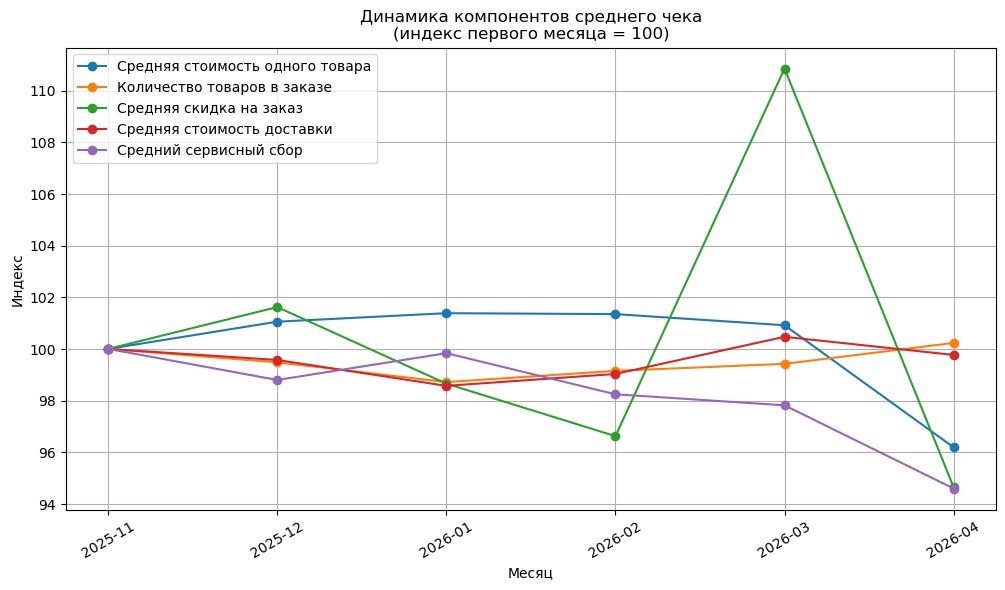

In [29]:
components = ['avg_item_price', 'items_per_order', 'discount_per_order', 'avg_delivery_fee', 'avg_service_fee']
components_index = monthly[['month'] + components].copy()

for col in components:
    components_index[col] = (components_index[col] / components_index[col].iloc[0] * 100)

plt.figure(figsize=(12, 6))

plt.plot(components_index['month'], components_index['avg_item_price'], marker='o', label='Средняя стоимость одного товара')
plt.plot(components_index['month'], components_index['items_per_order'], marker='o', label='Количество товаров в заказе')
plt.plot(components_index['month'], components_index['discount_per_order'], marker='o', label='Средняя скидка на заказ')
plt.plot(components_index['month'], components_index['avg_delivery_fee'], marker='o', label='Средняя стоимость доставки')
plt.plot(components_index['month'], components_index['avg_service_fee'], marker='o', label='Средний сервисный сбор')
plt.title('Динамика компонентов среднего чека\n(индекс первого месяца = 100)')

plt.xlabel('Месяц')
plt.ylabel('Индекс')
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)

plt.show()

Для оценки влияния промоактивности на динамику оборота рассмотрим долю скидок в GMV. Метрика показывает, какую часть оборота составляют предоставленные клиентам скидки.

Доля скидок в GMV заметно увеличивается в марте и снижается в апреле. Это указывает на то, что в марте могла действовать более сильная скидочная механика, которая поддерживала спрос, количество заказов и конверсию. В апреле доля скидок возвращается ближе к уровню предыдущих месяцев, что могло привести к исчезновению мартовского uplift-эффекта.

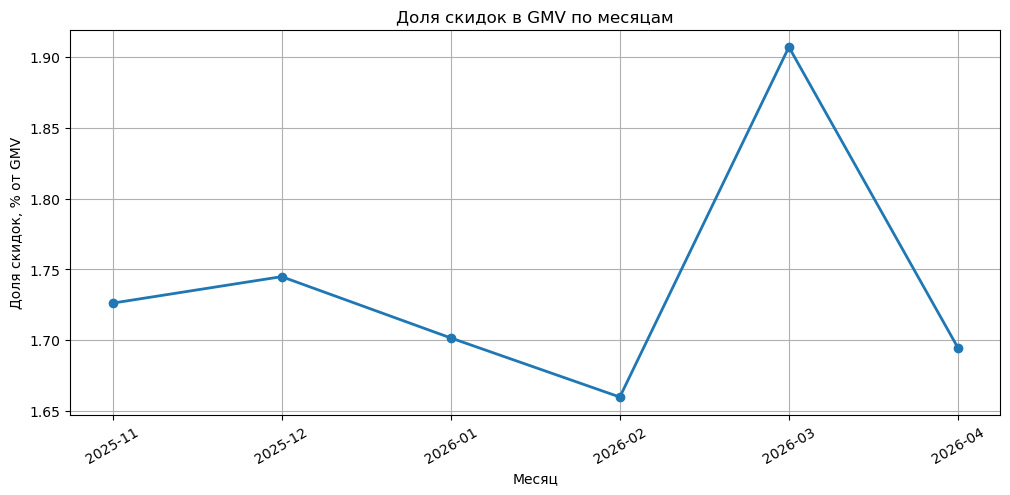

In [30]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly['month'],
    monthly['discount_share_gmv'] * 100,
    marker='o',
    linewidth=2
)

plt.title('Доля скидок в GMV по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Доля скидок, % от GMV')

plt.grid(True)
plt.xticks(rotation=30)

plt.show()

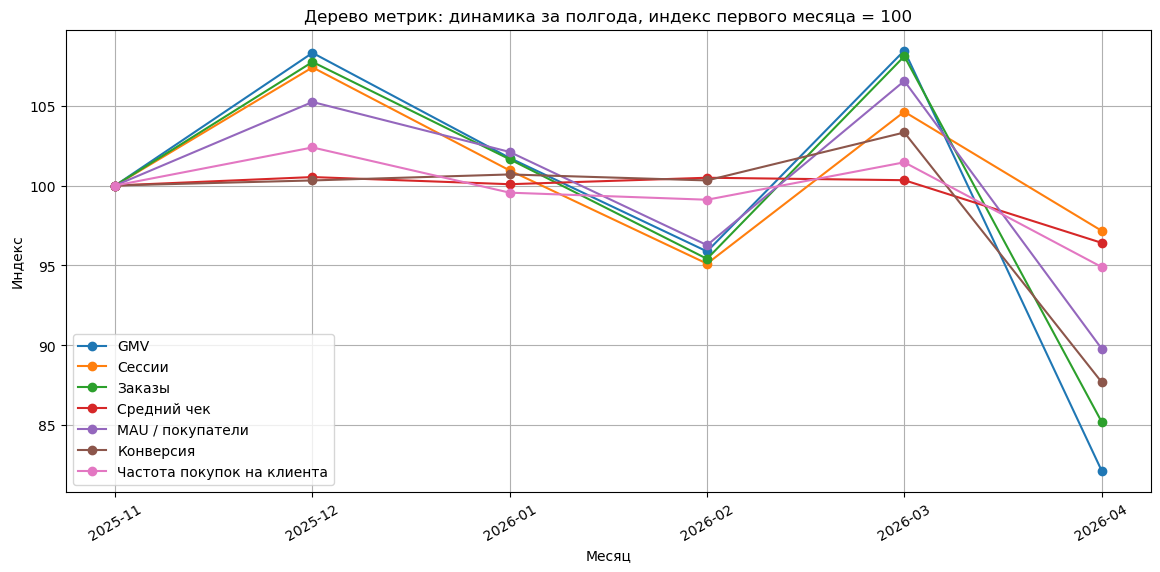

In [31]:
index_cols = {
    'gmv': 'GMV',
    'sessions': 'Сессии', 
    'orders': 'Заказы',
    'aov_gmv': 'Средний чек',
    'buyers': 'MAU / покупатели',
    'session_to_purchase_cr': 'Конверсия',
    'orders_per_buyer': 'Частота покупок на клиента'
}

monthly_index = monthly[['month'] + list(index_cols.keys())].copy()

for col in index_cols.keys():
    monthly_index[col] = monthly_index[col] / monthly_index[col].iloc[0] * 100

plt.figure(figsize=(14, 6))

for col, label in index_cols.items():
    plt.plot(monthly_index['month'], monthly_index[col], marker='o', label=label)

plt.title('Дерево метрик: динамика за полгода, индекс первого месяца = 100')
plt.xlabel('Месяц')
plt.ylabel('Индекс')
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)
plt.show()

### Анализ воронки

Анализ воронки показывает, что основная просадка возникает не на верхних этапах: пользователи продолжают заходить в сервис, искать товары и просматривать карточки. Наиболее заметное ухудшение наблюдается на этапе «просмотр карточки товара → добавление в корзину». Это хорошо согласуется с гипотезой о влиянии скидок: если промоусловия стали менее привлекательными, пользователь может просматривать товар, но реже принимать решение добавить его в корзину.

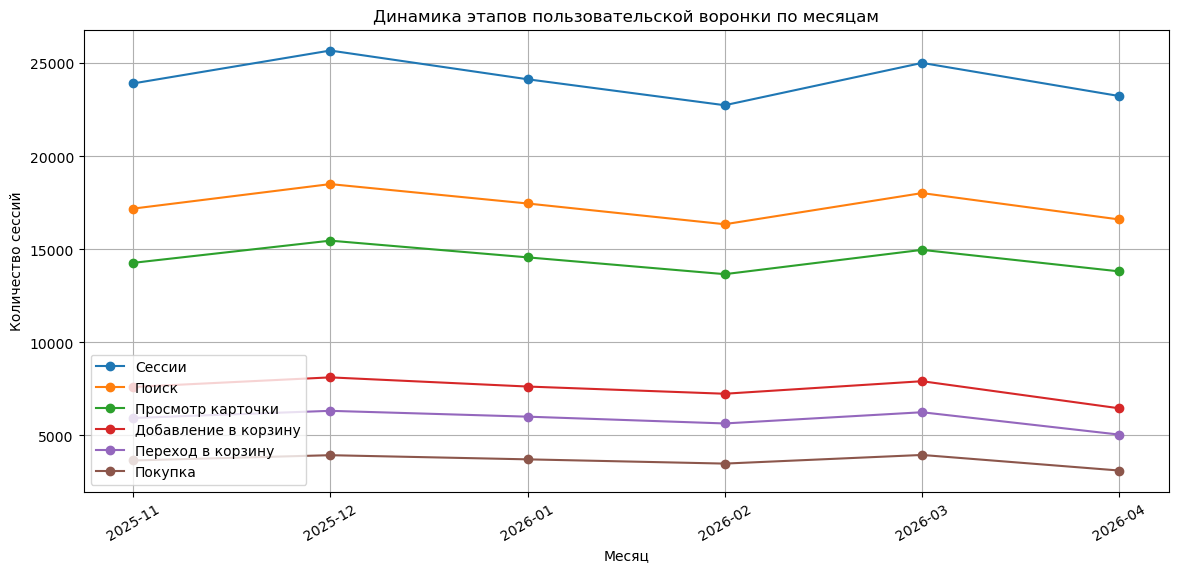

In [32]:
funnel_steps = {
    'sessions': 'Сессии',
    'searches': 'Поиск',
    'card_views': 'Просмотр карточки',
    'add_to_cart': 'Добавление в корзину',
    'cart_visits': 'Переход в корзину',
    'purchases': 'Покупка'
}

plt.figure(figsize=(14, 6))

for col, label in funnel_steps.items():
    plt.plot(monthly['month'], monthly[col], marker='o', label=label)

plt.title('Динамика этапов пользовательской воронки по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Количество сессий')
plt.legend(loc='lower left')
plt.grid(True)
plt.xticks(rotation=30)
plt.show()

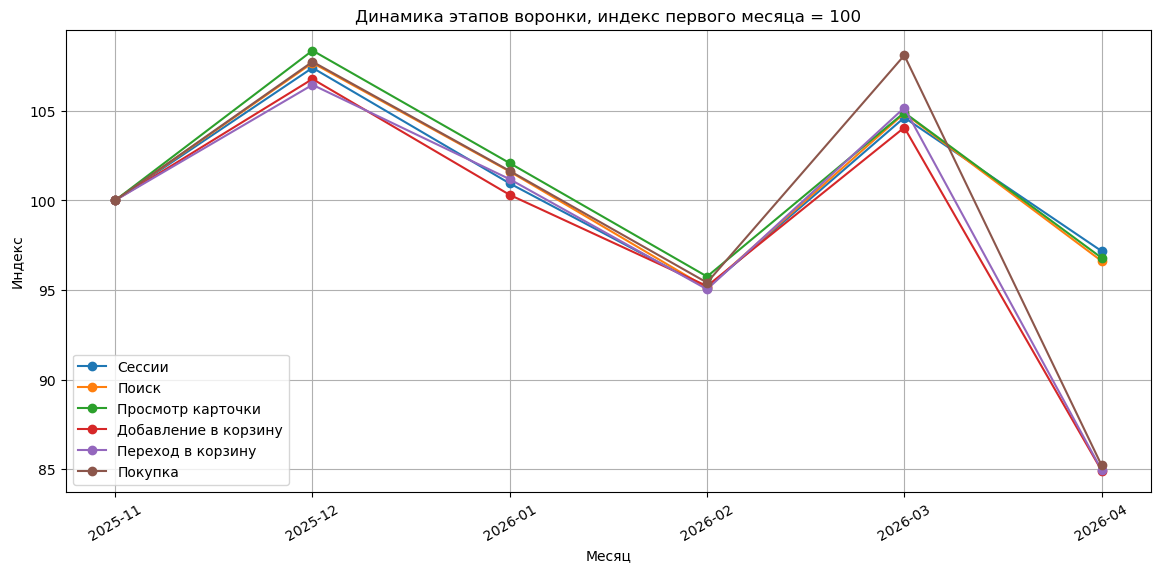

In [33]:
monthly_funnel_index = monthly[['month'] + list(funnel_steps.keys())].copy()

for col in funnel_steps.keys():
    monthly_funnel_index[col] = (
        monthly_funnel_index[col] / monthly_funnel_index[col].iloc[0] * 100
    )

plt.figure(figsize=(14, 6))

for col, label in funnel_steps.items():
    plt.plot(monthly_funnel_index['month'], monthly_funnel_index[col], marker='o', label=label)

plt.title('Динамика этапов воронки, индекс первого месяца = 100')
plt.xlabel('Месяц')
plt.ylabel('Индекс')
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)
plt.show()

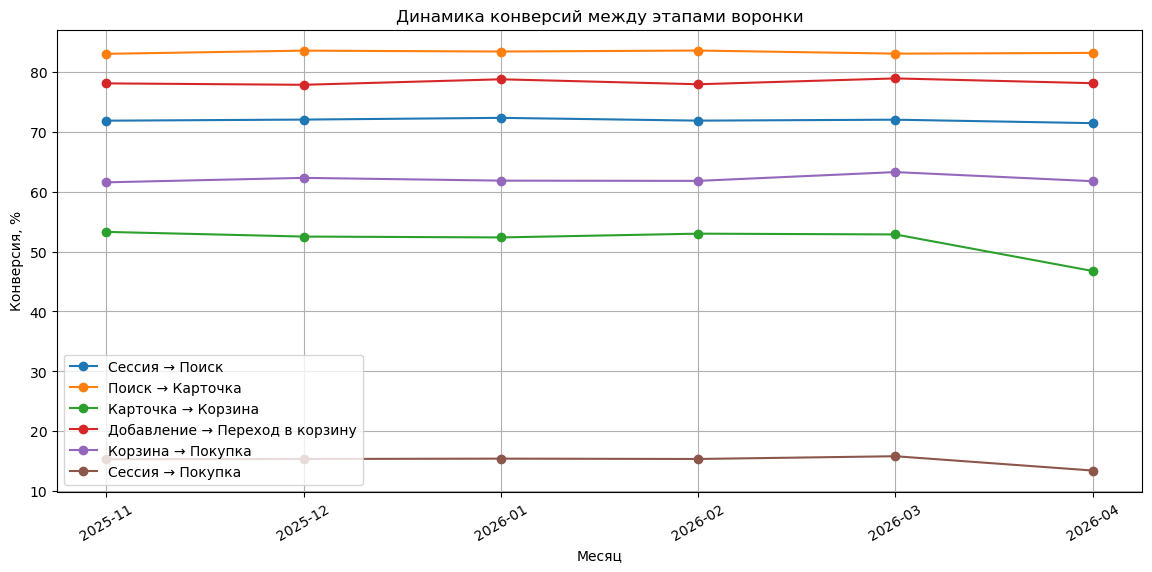

In [34]:
funnel_cr = {
    'visit_to_search_cr': 'Сессия → Поиск',
    'search_to_card_cr': 'Поиск → Карточка',
    'card_to_cart_cr': 'Карточка → Корзина',
    'cart_add_to_cart_visit_cr': 'Добавление → Переход в корзину',
    'cart_to_purchase_cr': 'Корзина → Покупка',
    'session_to_purchase_cr': 'Сессия → Покупка'
}

plt.figure(figsize=(14, 6))

for col, label in funnel_cr.items():
    plt.plot(monthly['month'], monthly[col] * 100, marker='o', label=label)

plt.title('Динамика конверсий между этапами воронки')
plt.xlabel('Месяц')
plt.ylabel('Конверсия, %')
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)
plt.show()

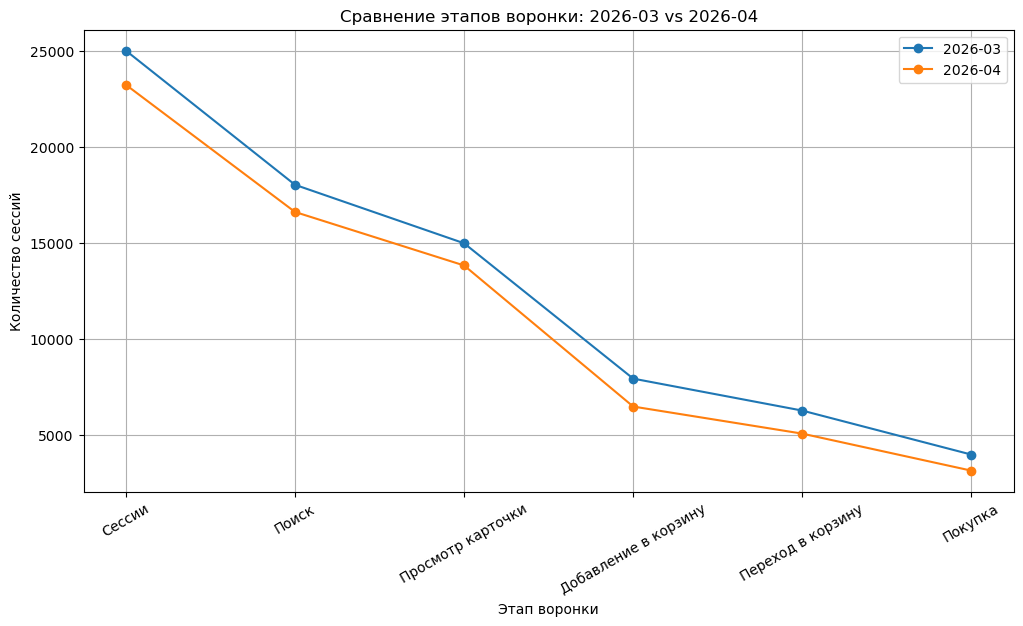

In [35]:
prev_month = monthly['month'].iloc[-2]
last_month = monthly['month'].iloc[-1]

compare_funnel = monthly[
    monthly['month'].isin([prev_month, last_month])
][['month'] + list(funnel_steps.keys())]

compare_funnel_long = compare_funnel.melt(
    id_vars='month',
    value_vars=list(funnel_steps.keys()),
    var_name='step',
    value_name='value'
)

compare_funnel_long['step_name'] = compare_funnel_long['step'].map(funnel_steps)

plt.figure(figsize=(12, 6))

for month in compare_funnel_long['month'].unique():
    data = compare_funnel_long[compare_funnel_long['month'] == month]
    plt.plot(data['step_name'], data['value'], marker='o', label=str(month))

plt.title(f'Сравнение этапов воронки: {prev_month} vs {last_month}')
plt.xlabel('Этап воронки')
plt.ylabel('Количество сессий')
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)
plt.show()

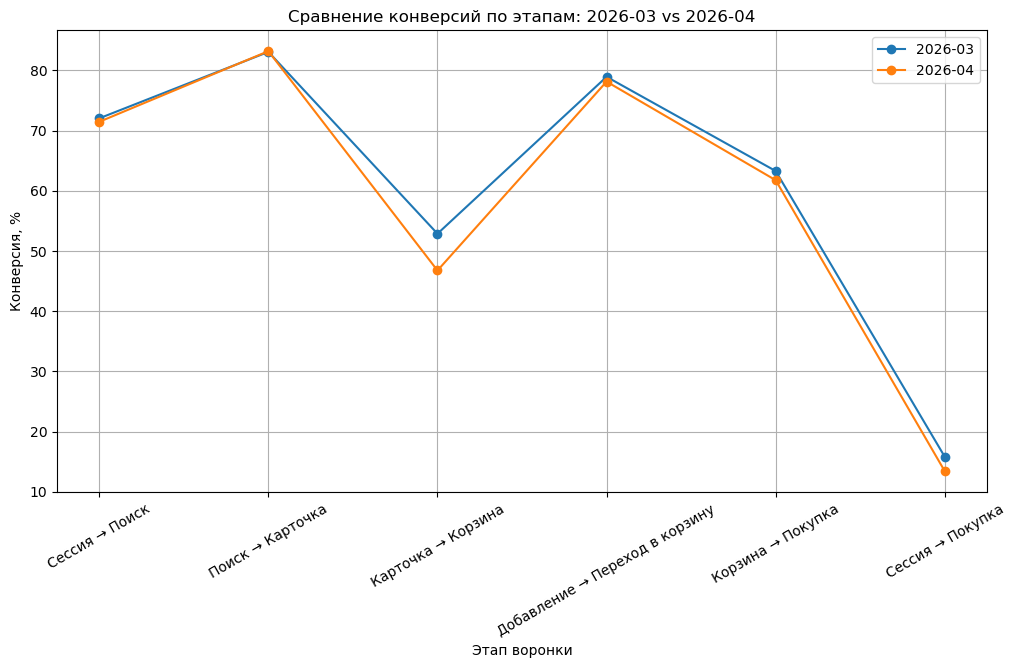

In [36]:
compare_cr = monthly[
    monthly['month'].isin([prev_month, last_month])
][['month'] + list(funnel_cr.keys())]

compare_cr_long = compare_cr.melt(
    id_vars='month',
    value_vars=list(funnel_cr.keys()),
    var_name='step',
    value_name='conversion'
)

compare_cr_long['step_name'] = compare_cr_long['step'].map(funnel_cr)
compare_cr_long['conversion'] = compare_cr_long['conversion'] * 100

plt.figure(figsize=(12, 6))

for month in compare_cr_long['month'].unique():
    data = compare_cr_long[compare_cr_long['month'] == month]
    plt.plot(data['step_name'], data['conversion'], marker='o', label=str(month))

plt.title(f'Сравнение конверсий по этапам: {prev_month} vs {last_month}')
plt.xlabel('Этап воронки')
plt.ylabel('Конверсия, %')
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)
plt.show()

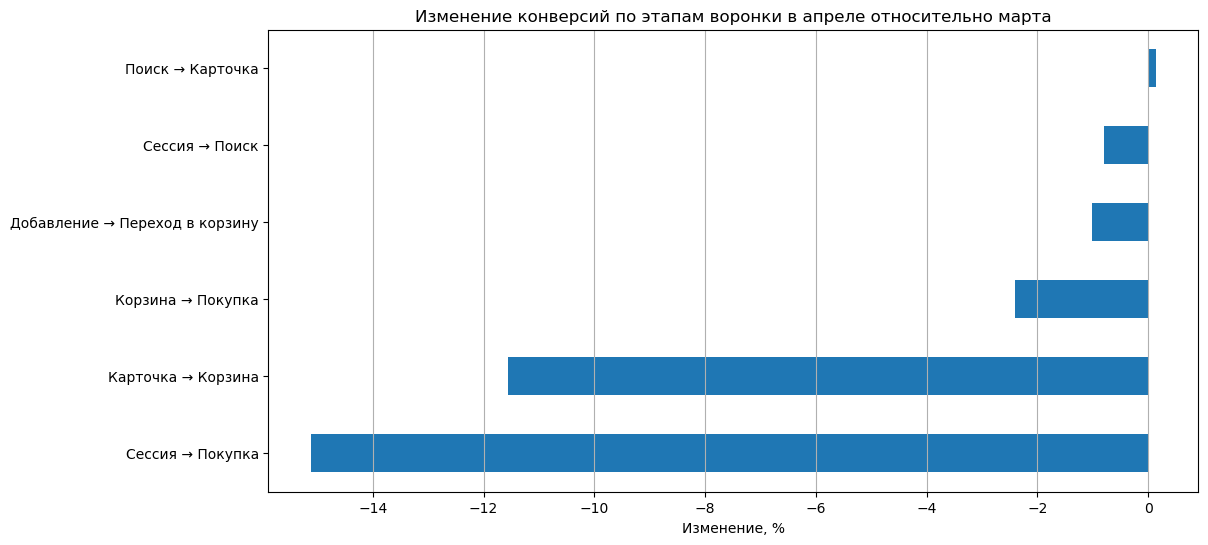

In [37]:
funnel_cr = {
    'visit_to_search_cr': 'Сессия → Поиск',
    'search_to_card_cr': 'Поиск → Карточка',
    'card_to_cart_cr': 'Карточка → Корзина',
    'cart_add_to_cart_visit_cr': 'Добавление → Переход в корзину',
    'cart_to_purchase_cr': 'Корзина → Покупка',
    'session_to_purchase_cr': 'Сессия → Покупка'
}

funnel_cr_change = {}

for col, label in funnel_cr.items():
    march_value = monthly.loc[monthly['month'] == '2026-03', col].iloc[0]
    april_value = monthly.loc[monthly['month'] == '2026-04', col].iloc[0]
    funnel_cr_change[label] = (april_value / march_value - 1) * 100

funnel_cr_change = pd.Series(funnel_cr_change).sort_values()

plt.figure(figsize=(12, 6))
funnel_cr_change.plot(kind='barh')
plt.title('Изменение конверсий по этапам воронки в апреле относительно марта')
plt.xlabel('Изменение, %')
plt.grid(axis='x')
plt.show()

### Промежуточные выводы

На агрегированном уровне установлено, что GMV в апреле снизился на 24.2%.

Основной вклад в снижение оборота внесло уменьшение количества заказов, тогда как влияние среднего чека оказалось менее существенным.

Анализ воронки показал, что снижение количества заказов объясняется не только уменьшением трафика, но и ухудшением конверсии.

Наиболее проблемным этапом является переход от просмотра карточки товара к добавлению товара в корзину. Эта просадка вероятно связана с тем, что относительно марта в апреле убрали скидку, что останавливает покупателей от покупки. 

На текущем этапе наиболее вероятная гипотеза состоит в том, что мартовская скидочная механика давала дополнительный прирост заказов и конверсии, а в апреле этот эффект исчез. Это могло привести к снижению привлекательности предложения для пользователя и просадке на этапе «карточка товара → добавление в корзину».

При этом падение наблюдается во многих сегментах, поэтому скидочная механика, вероятно, является важным фактором, но требует дополнительной проверки через статистические тесты.

### Изменения по срезам 

На предыдущем этапе было установлено, что падение GMV в апреле связано преимущественно со снижением количества заказов и ухудшением конверсии в покупку.

Далее проверим, не сконцентрирована ли просадка в отдельных сегментах: по платформам, городам, типам скидок, маркетинговому касанию, способам оплаты и источникам трафика.

In [38]:
def orders_slice_analysis(df, segment_col):
    slice_monthly = (
        df.groupby(['month', segment_col])
        .agg(
            gmv=('gross_merchandise_value', 'sum'),
            orders=('order_id', 'nunique'),
            buyers=('client_id', 'nunique'),
            aov=('gross_merchandise_value', 'mean')
        )
        .reset_index()
    )
    
    slice_monthly['orders_per_buyer'] = (
        slice_monthly['orders'] / slice_monthly['buyers']
    )
    
    return slice_monthly

def plot_gmv_by_segment(slice_monthly, segment_col, title):
    plt.figure(figsize=(12, 6))
    
    for segment in slice_monthly[segment_col].dropna().unique():
        data = slice_monthly[slice_monthly[segment_col] == segment]
        plt.plot(data['month'], data['gmv'], marker='o', label=str(segment))
    
    plt.title(title)
    plt.xlabel('Месяц')
    plt.ylabel('GMV')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=30)
    plt.show()    

In [39]:
def plot_index_gmv_by_segment(slice_monthly, segment_col, title):
    index_df = slice_monthly.copy()
    
    index_df['gmv_index'] = (
        index_df
        .groupby(segment_col)['gmv']
        .transform(lambda x: x / x.iloc[0] * 100)
    )
    
    plt.figure(figsize=(12, 6))
    
    for segment in index_df[segment_col].dropna().unique():
        data = index_df[index_df[segment_col] == segment]
        plt.plot(data['month'], data['gmv_index'], marker='o', label=str(segment))
    
    plt.title(title)
    plt.xlabel('Месяц')
    plt.ylabel('Индекс GMV, первый месяц = 100')
    plt.legend()
    plt.grid(True)
    plt.xticks(rotation=30)
    plt.show()

In [40]:
def plot_gmv_share_by_segment(slice_monthly, segment_col, title):

    share_df = slice_monthly.copy()

    # общий GMV месяца
    share_df['total_gmv_month'] = (
        share_df
        .groupby('month')['gmv']
        .transform('sum')
    )

    # доля сегмента в GMV месяца
    share_df['gmv_share'] = (
        share_df['gmv']
        / share_df['total_gmv_month']
        * 100
    )

    plt.figure(figsize=(12, 6))

    for segment in share_df[segment_col].dropna().unique():

        data = share_df[
            share_df[segment_col] == segment
        ]

        plt.plot(
            data['month'],
            data['gmv_share'],
            marker='o',
            label=str(segment)
        )

    plt.title(title)
    plt.xlabel('Месяц')
    plt.ylabel('Доля GMV, %')
    plt.legend()
    #plt.yscale('log')
    plt.grid(True)
    plt.xticks(rotation=30)

    plt.show()

In [41]:
def segment_march_april_change(slice_monthly, segment_col, metric):
    prev_month = slice_monthly['month'].sort_values().unique()[-2]
    last_month = slice_monthly['month'].sort_values().unique()[-1]
    
    pivot = (
        slice_monthly
        .pivot(index=segment_col, columns='month', values=metric)
        .reset_index()
    )
    
    pivot['change_%'] = (
        pivot[last_month] / pivot[prev_month] - 1
    ) * 100
    
    pivot = pivot.sort_values('change_%')
    
    return pivot, prev_month, last_month

def plot_segment_change(slice_monthly, segment_col, metric, title):
    change_df, prev_month, last_month = segment_march_april_change(
        slice_monthly, segment_col, metric
    )
    
    plt.figure(figsize=(10, 6))
    plt.barh(change_df[segment_col].astype(str), change_df['change_%'])
    plt.title(f'{title}: {prev_month} → {last_month}')
    plt.xlabel('Изменение, %')
    plt.ylabel(segment_col)
    plt.grid(axis='x')
    plt.show()
    
    return change_df    

#### Срез по платформам

По платформам снижение GMV наблюдается во всех сегментах, то есть падение оборота не связано только с одной платформой.

Наиболее сильная просадка наблюдается на Web: GMV снизился на 29.5% относительно марта. На iOS снижение составило 25.2%, на Android — 21.2%.

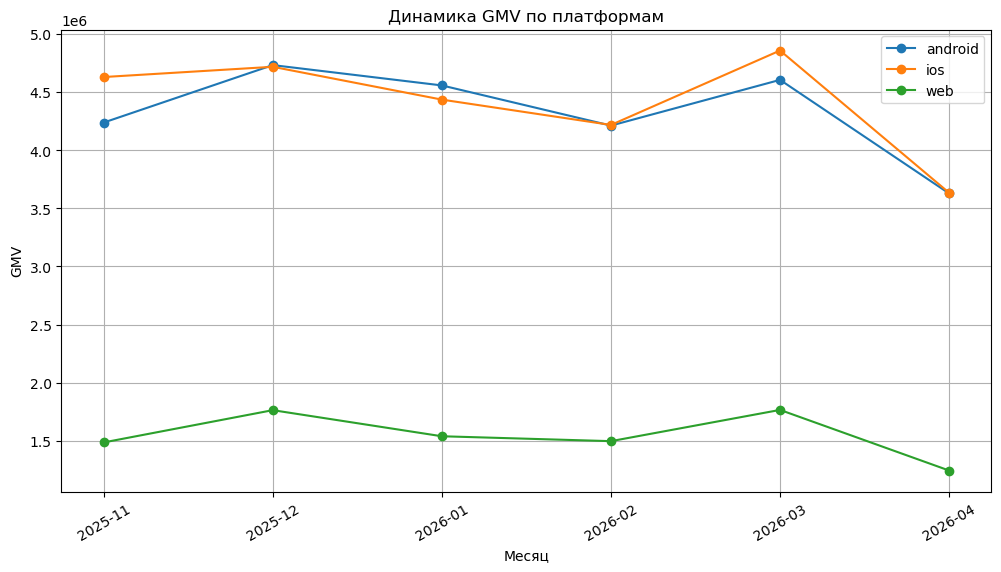

In [42]:
platform_orders = orders_slice_analysis(orders, 'platform')
plot_gmv_by_segment(
    platform_orders,
    'platform',
    'Динамика GMV по платформам'
)

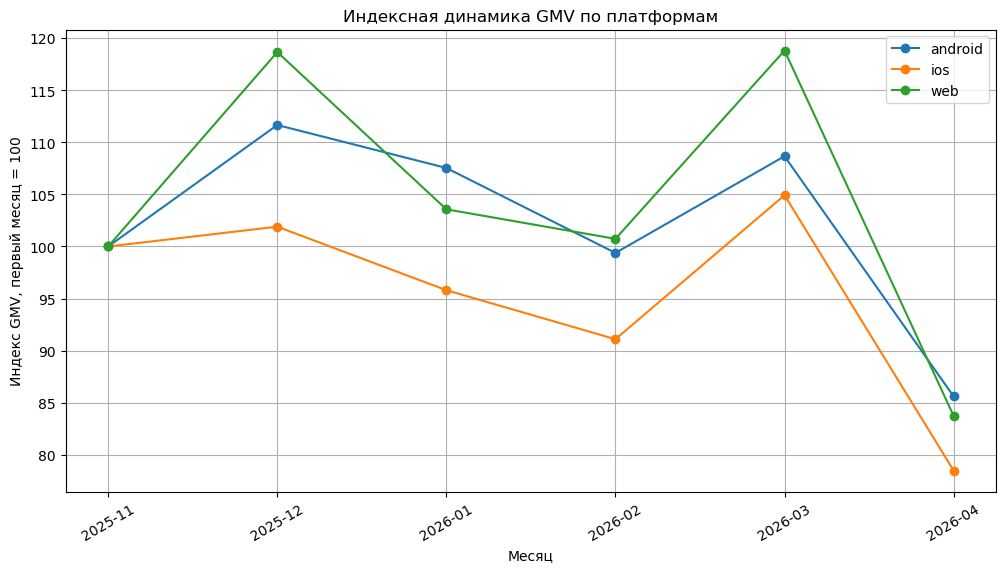

In [43]:
plot_index_gmv_by_segment(
    platform_orders,
    'platform',
    'Индексная динамика GMV по платформам'
)

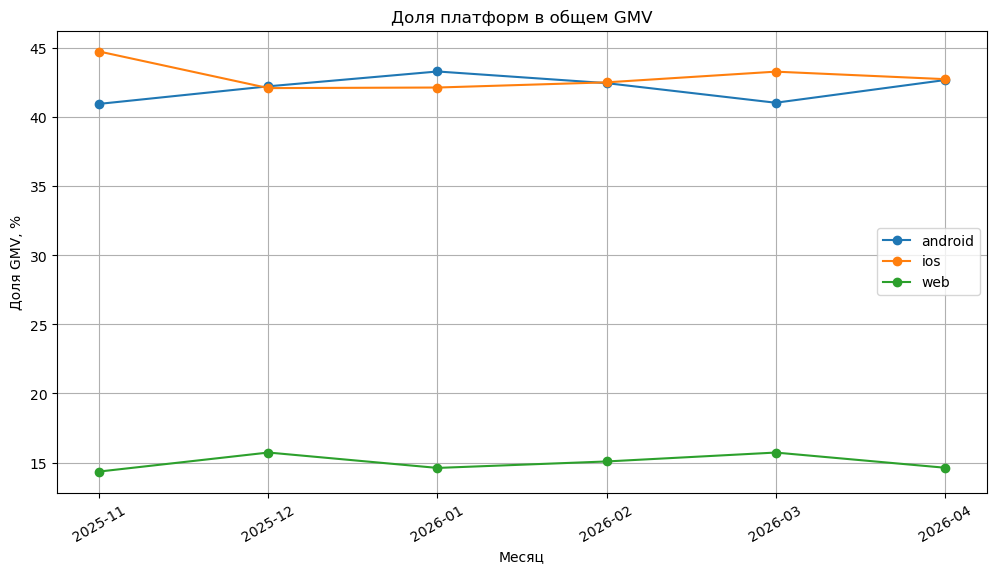

In [44]:
plot_gmv_share_by_segment(
    platform_orders,
    'platform',
    'Доля платформ в общем GMV'
)

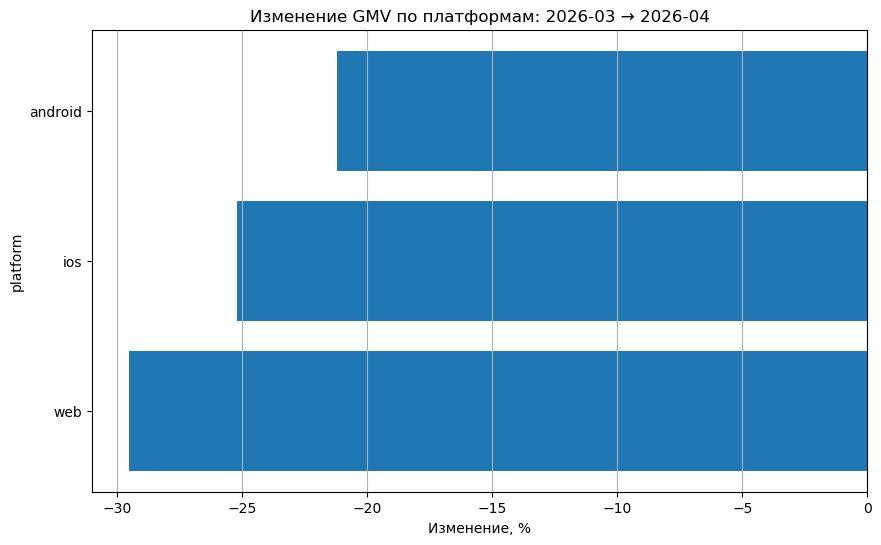

month,platform,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,change_%
2,web,1486660.45,1764146.55,1539712.24,1497566.68,1766318.24,1244874.41,-29.521511
1,ios,4629428.88,4717472.84,4435173.82,4217340.41,4857348.95,3633709.84,-25.191501
0,android,4237842.28,4732055.24,4557282.49,4211645.48,4605026.84,3627926.87,-21.218117


In [45]:
plot_segment_change(
    platform_orders,
    'platform',
    'gmv',
    'Изменение GMV по платформам'
)

#### Срез по городам

По городам падение GMV также наблюдается во всех сегментах, однако выражено неравномерно.

Наиболее сильное снижение произошло в Новосибирске: GMV упал на 38.1% относительно марта. Также заметная просадка наблюдается в Казани: -33.3%.

Москва, Санкт-Петербург и Екатеринбург также снижаются, но темпы падения ближе к общему уровню сервиса.

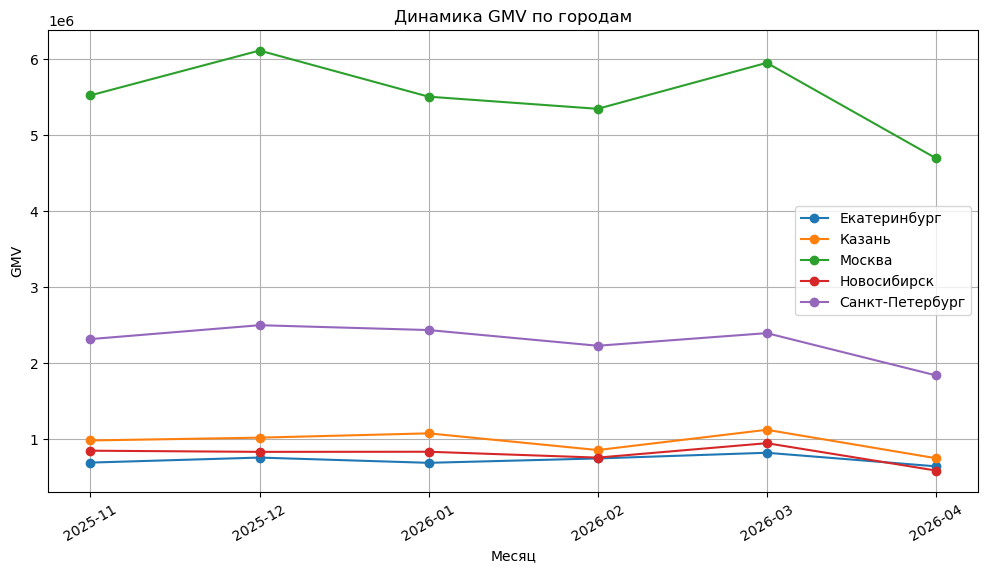

In [46]:
city_orders = orders_slice_analysis(orders, 'city')

plot_gmv_by_segment(
     city_orders,
    'city',
    'Динамика GMV по городам'
)

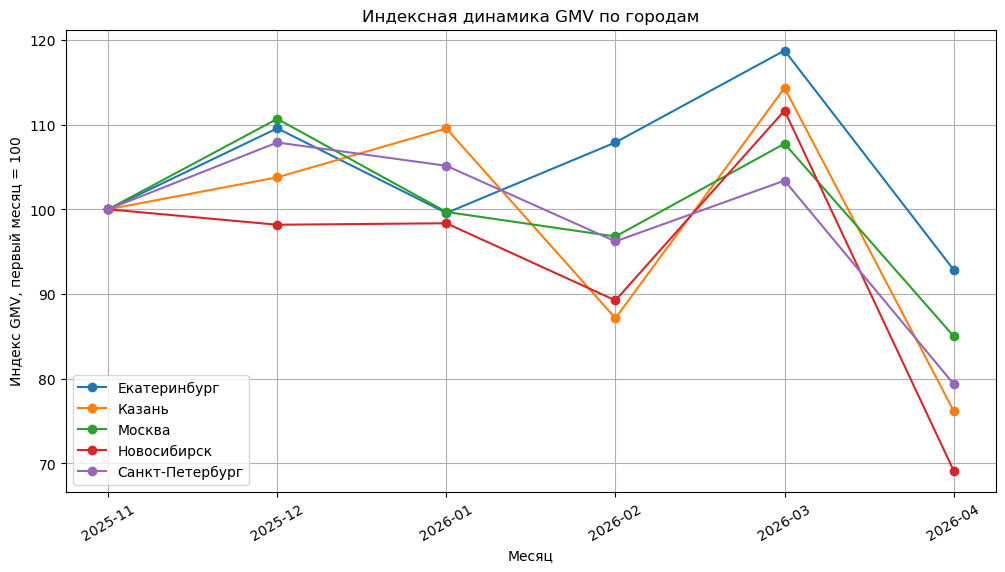

In [47]:
plot_index_gmv_by_segment(
    city_orders,
    'city',
    'Индексная динамика GMV по городам'
)

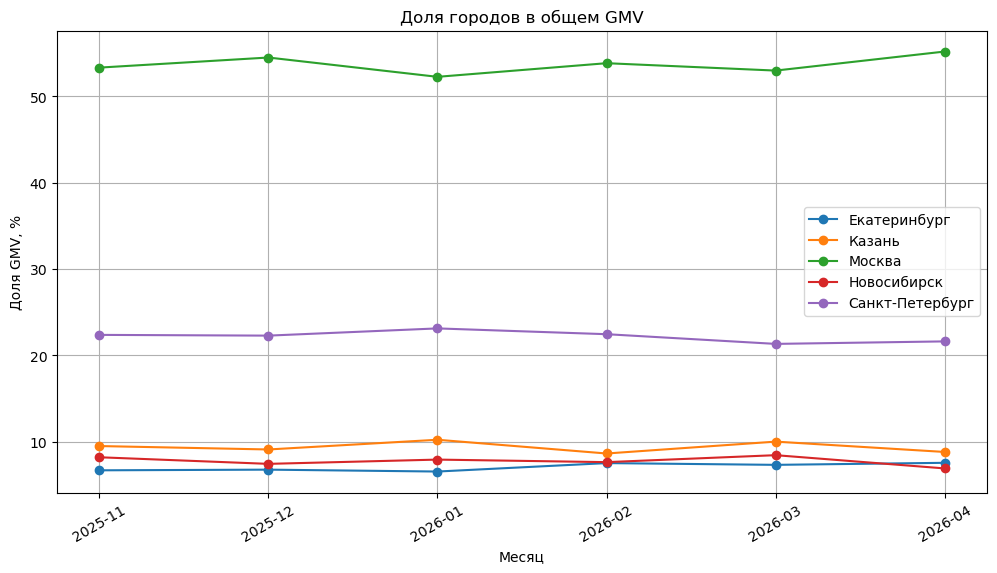

In [48]:
plot_gmv_share_by_segment(
    city_orders,
    'city',
    'Доля городов в общем GMV'
)

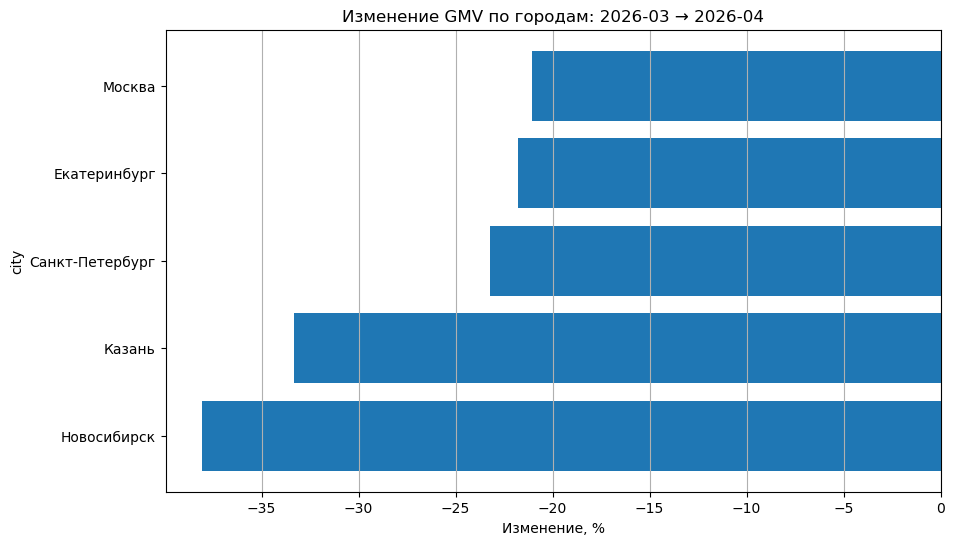

month,city,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,change_%
3,Новосибирск,846708.77,831274.53,832772.72,755642.02,945370.08,585624.30,-38.053434
1,Казань,981172.92,1018172.81,1074850.38,855048.68,1121737.86,747813.29,-33.334399
4,Санкт-Петербург,2314801.99,2497426.29,2433700.20,2227168.46,2393165.34,1837656.61,-23.212300
0,Екатеринбург,690120.09,756110.12,687092.10,744618.12,819455.74,640930.04,-21.785887
2,Москва,5521127.84,6110690.88,5503753.15,5344075.29,5948965.01,4694486.88,-21.087334


In [49]:
plot_segment_change(
    city_orders,
    'city',
    'gmv',
    'Изменение GMV по городам'
)

#### Срез по типу скидки

По типам скидок сильнее всего просели заказы с промо-механиками: free_delivery, fixed_amount и percent.

GMV заказов без скидки снизился на 20.5%, тогда как GMV заказов с бесплатной доставкой упал почти на 40%, а с фиксированной скидкой — на 36.4%.

Это может указывать на изменение эффективности промо или снижение объема заказов, стимулированных скидками. Однако на основании только GMV нельзя сделать окончательный вывод: необходимо проверить, изменилось ли количество заказов с каждым типом скидки и доля скидочных заказов в общем объеме.

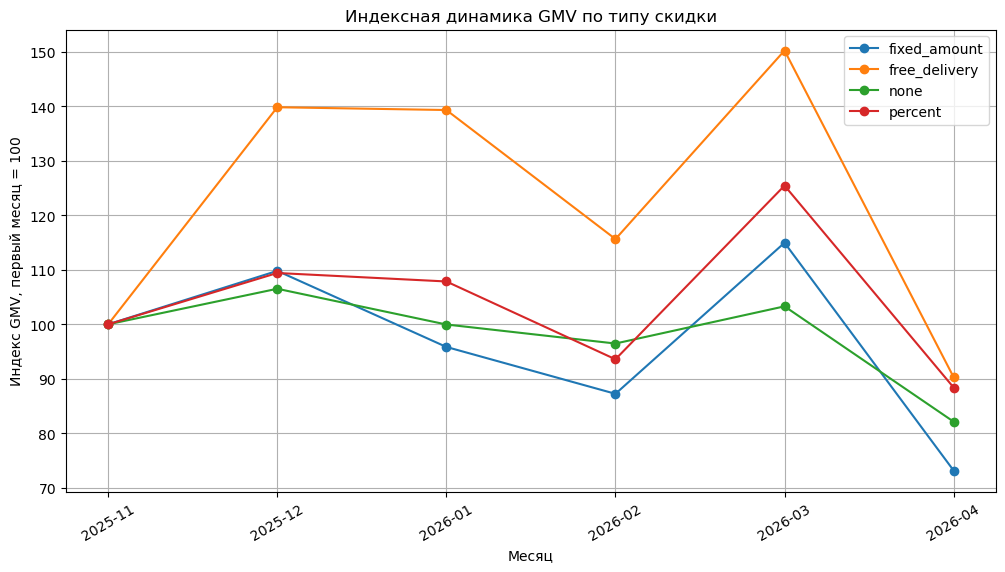

In [50]:
discount_orders = orders_slice_analysis(orders, 'discount_type')

plot_index_gmv_by_segment(
    discount_orders,
    'discount_type',
    'Индексная динамика GMV по типу скидки'
)

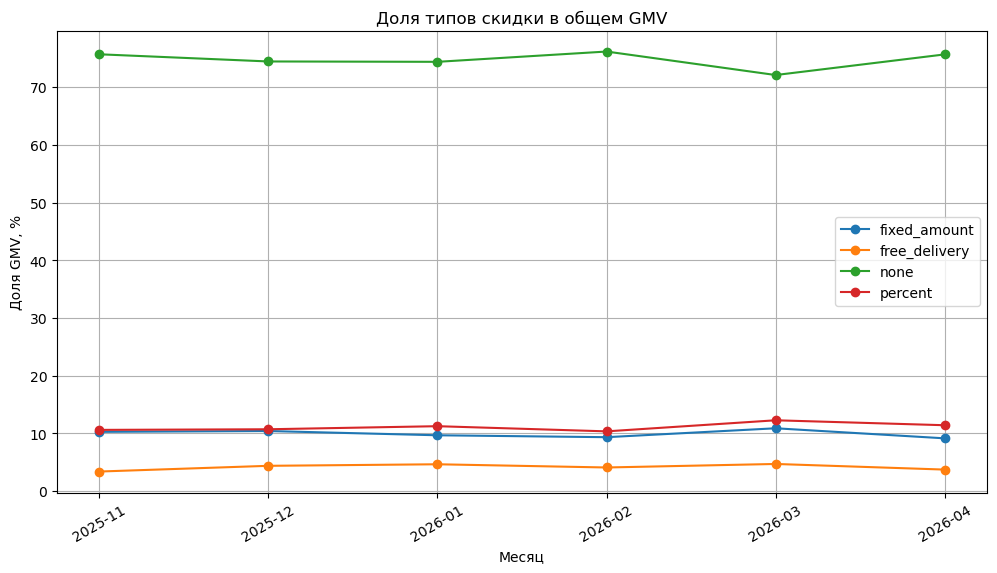

In [51]:
plot_gmv_share_by_segment(
    discount_orders,
    'discount_type',
    'Доля типов скидки в общем GMV'
)

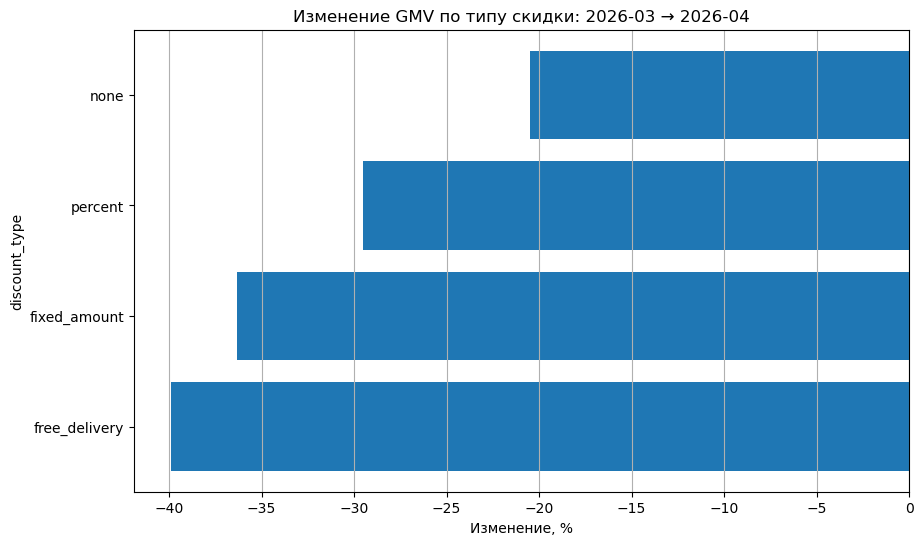

month,discount_type,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,change_%
1,free_delivery,352514.75,492923.42,491125.40,407663.50,529598.52,318322.16,-39.893684
0,fixed_amount,1064462.18,1168867.61,1020278.39,928721.16,1223795.60,778889.59,-36.354601
3,percent,1099521.15,1203073.27,1185963.21,1028954.27,1379352.44,972034.59,-29.529643
2,none,7837433.53,8348810.33,7834801.55,7561213.64,8095947.47,6437264.78,-20.487814


In [52]:
plot_segment_change(
    discount_orders,
    'discount_type',
    'gmv',
    'Изменение GMV по типу скидки'
)

#### Срез по маркетинговой коммуникации

GMV снизился как у заказов, связанных с маркетинговыми коммуникациями, так и у заказов без маркетингового касания.

Маркетинговые заказы просели сильнее: -28.2% против -24.0% у немаркетинговых заказов. Однако разница не настолько велика, чтобы считать маркетинг единственной причиной падения GMV.

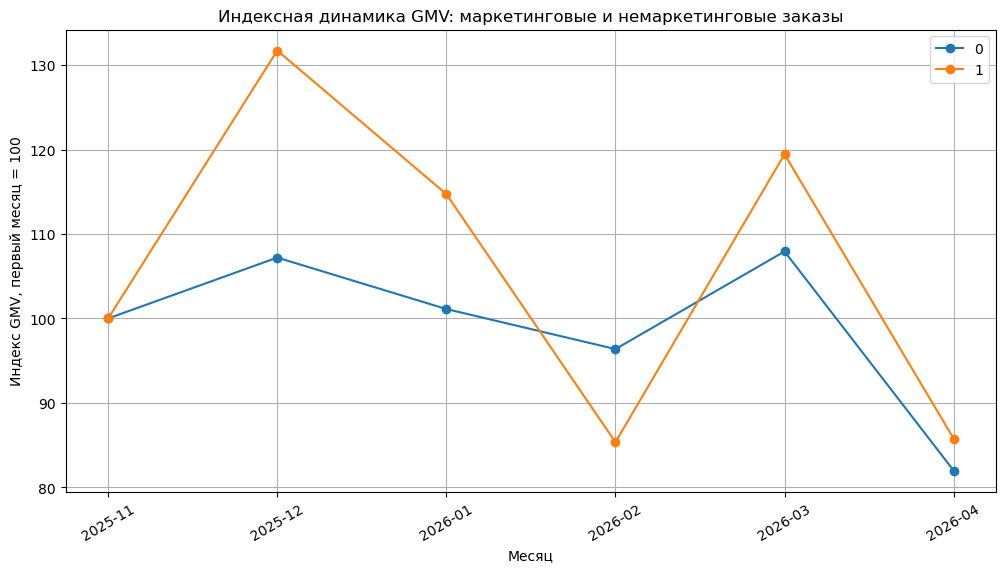

In [53]:
marketing_touch_orders = orders_slice_analysis(orders, 'is_marketing_touched')

plot_index_gmv_by_segment(
    marketing_touch_orders,
    'is_marketing_touched',
    'Индексная динамика GMV: маркетинговые и немаркетинговые заказы'
)

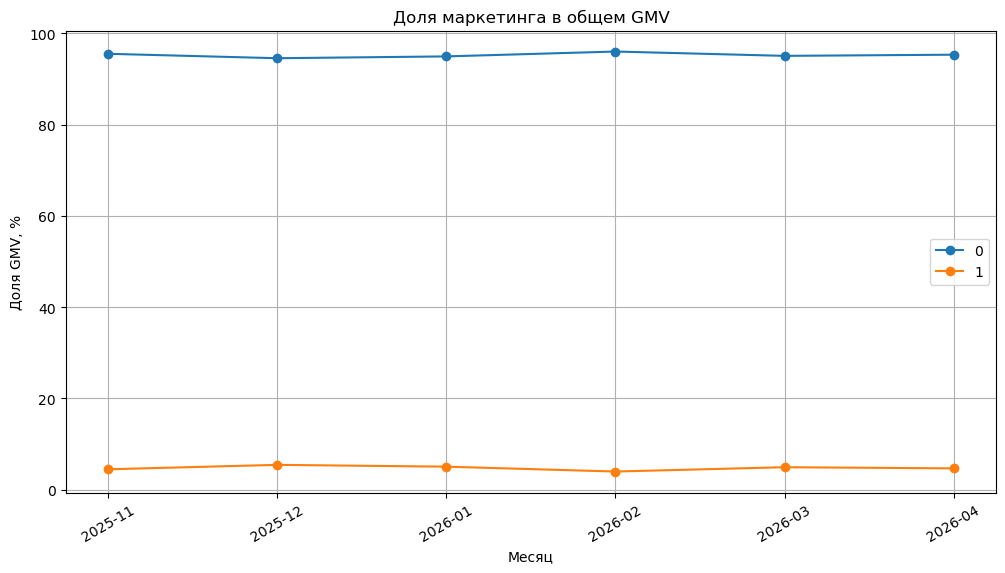

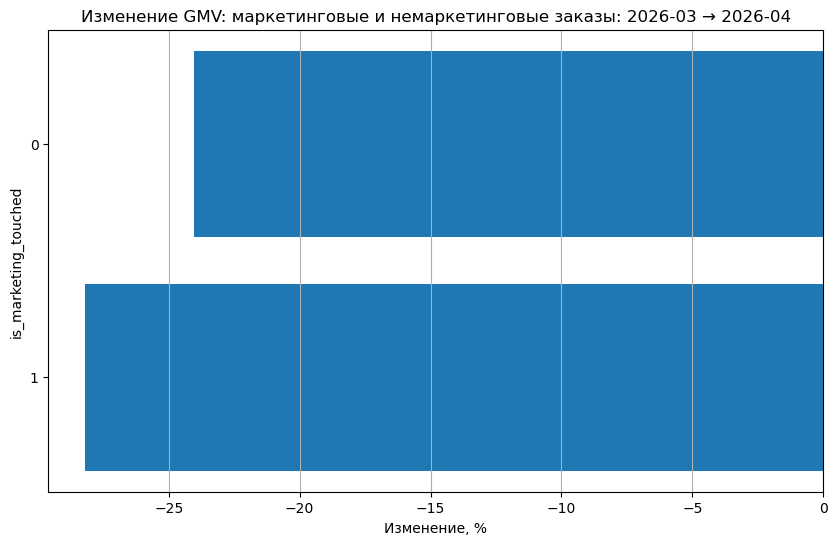

month,is_marketing_touched,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,change_%
1,1,464985.01,612473.49,533410.22,396836.30,555382.22,398821.46,-28.189732
0,0,9888946.60,10601201.14,9998758.33,9529716.27,10673311.81,8107689.66,-24.037733


In [54]:
plot_gmv_share_by_segment(
    marketing_touch_orders,
    'is_marketing_touched',
    'Доля маркетинга в общем GMV'
)

plot_segment_change(
    marketing_touch_orders,
    'is_marketing_touched',
    'gmv',
    'Изменение GMV: маркетинговые и немаркетинговые заказы'
)

#### Срез по типу оплаты

По способам оплаты снижение GMV наблюдается во всех группах.

Наиболее заметно просели заказы с оплатой картой: -25.7%. Однако карта является основным способом оплаты, поэтому такая динамика может отражать общий тренд сервиса, а не специфическую проблему платежного метода.

Сильной аномалии, указывающей на техническую проблему только в одном способе оплаты, не видно. Этот срез не выглядит основной причиной падения оборота.

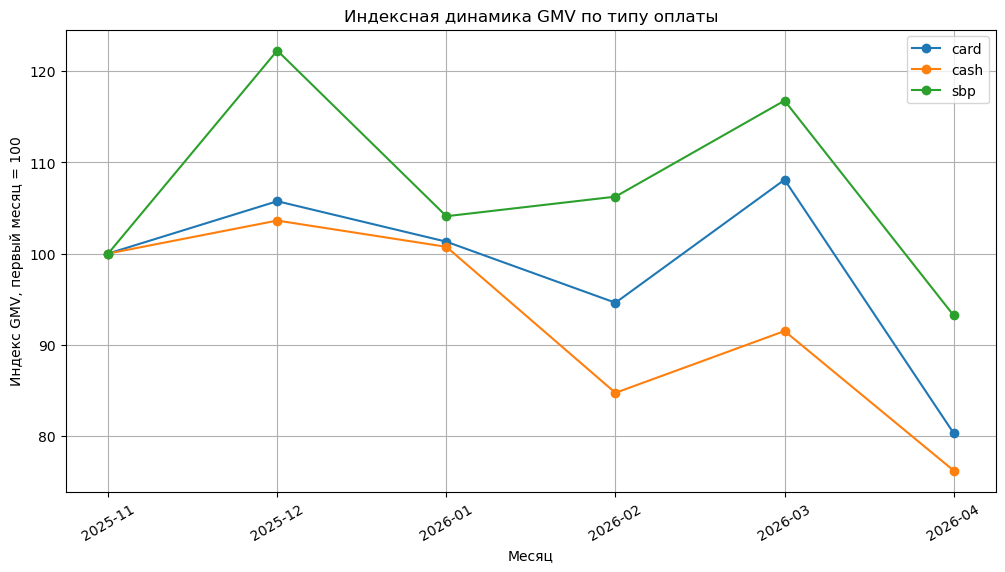

In [55]:
payment_orders = orders_slice_analysis(orders, 'payment_method')

plot_index_gmv_by_segment(
    payment_orders,
    'payment_method',
    'Индексная динамика GMV по типу оплаты'
)

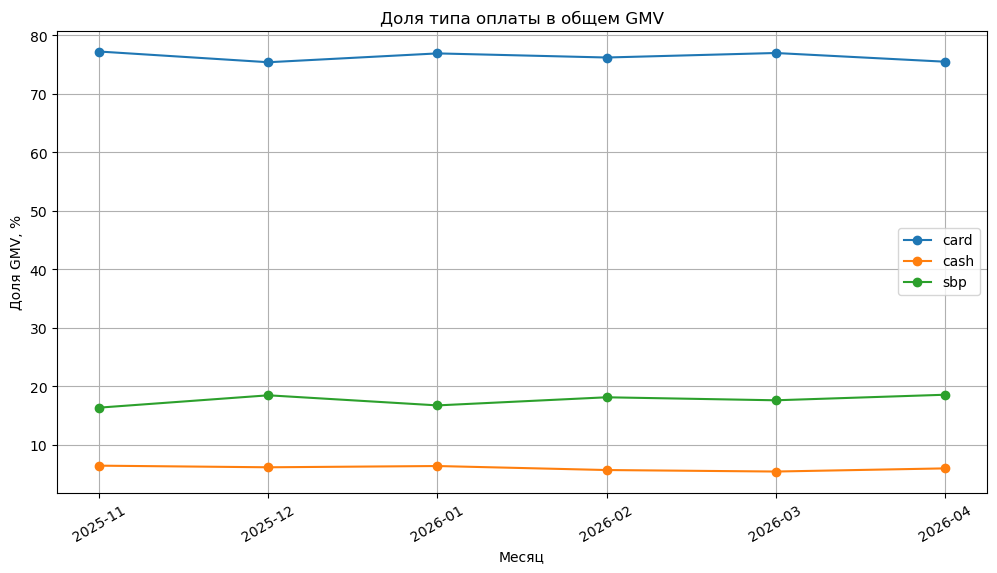

In [56]:
plot_gmv_share_by_segment(
    payment_orders,
    'payment_method',
    'Доля типа оплаты в общем GMV'
)

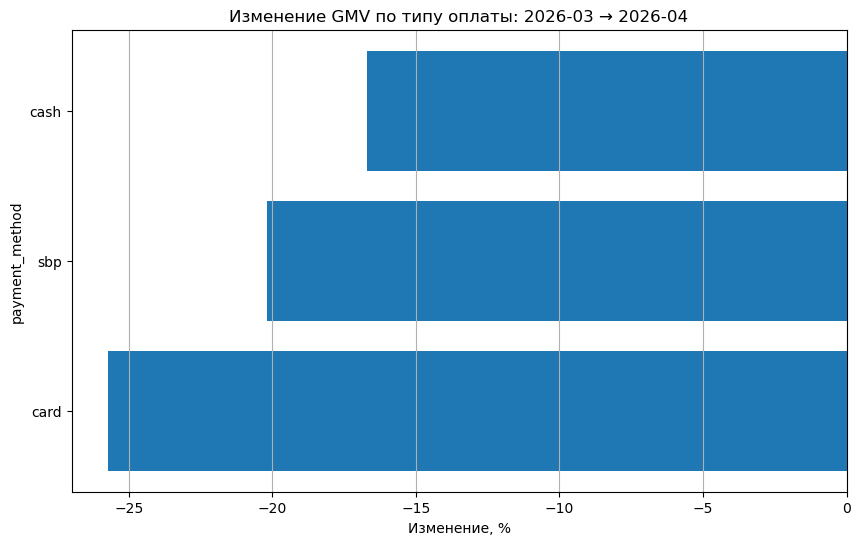

month,payment_method,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,change_%
0,card,7995816.66,8454664.08,8099839.91,7564465.31,8643269.17,6421497.45,-25.705224
2,sbp,1692715.48,2069539.61,1762027.57,1798318.86,1976563.24,1577935.56,-20.167717
1,cash,665399.47,689470.94,670301.07,563768.40,608861.62,507078.11,-16.717019


In [57]:
plot_segment_change(
    payment_orders,
    'payment_method',
    'gmv',
    'Изменение GMV по типу оплаты'
)

#### Срез по источникам трафика

In [58]:
traffic_monthly = (
    funnel
    .groupby(['month', 'traffic_source'])
    .agg(
        sessions=('session_id', 'nunique'),
        clients=('client_id', 'nunique'),
        purchases=('purchase', 'sum')
    )
    .reset_index()
)

traffic_monthly['session_to_purchase_cr'] = (
    traffic_monthly['purchases']
    / traffic_monthly['sessions']
)

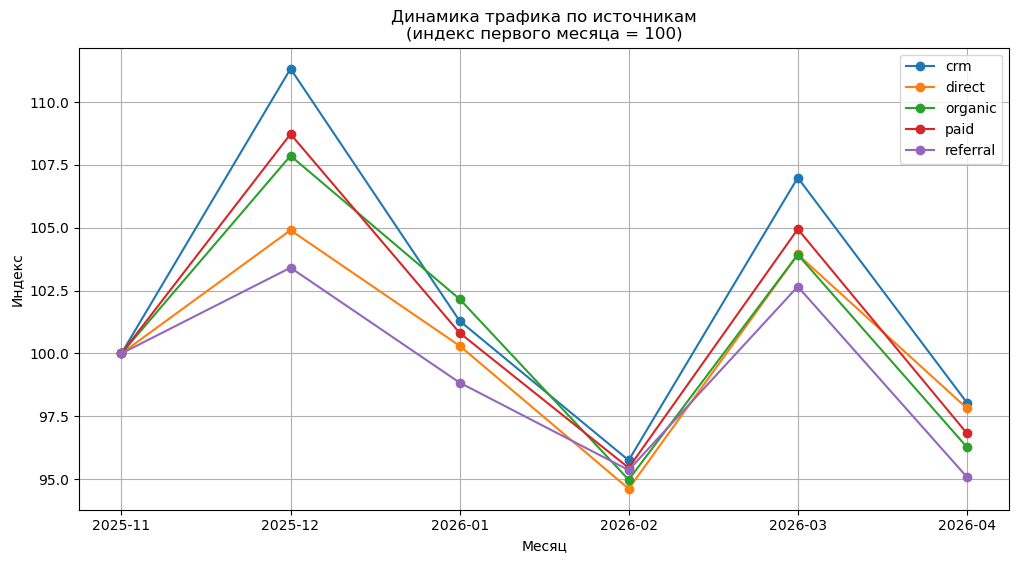

In [59]:
traffic_index = traffic_monthly.copy()

traffic_index['sessions_index'] = (
    traffic_index
    .groupby('traffic_source')['sessions']
    .transform(lambda x: x / x.iloc[0] * 100)
)

plt.figure(figsize=(12, 6))

for source in traffic_index['traffic_source'].dropna().unique():

    data = traffic_index[
        traffic_index['traffic_source'] == source
    ]

    plt.plot(
        data['month'],
        data['sessions_index'],
        marker='o',
        label=source
    )

plt.title('Динамика трафика по источникам\n(индекс первого месяца = 100)')
plt.xlabel('Месяц')
plt.ylabel('Индекс')
plt.legend()
plt.grid(True)
plt.show()

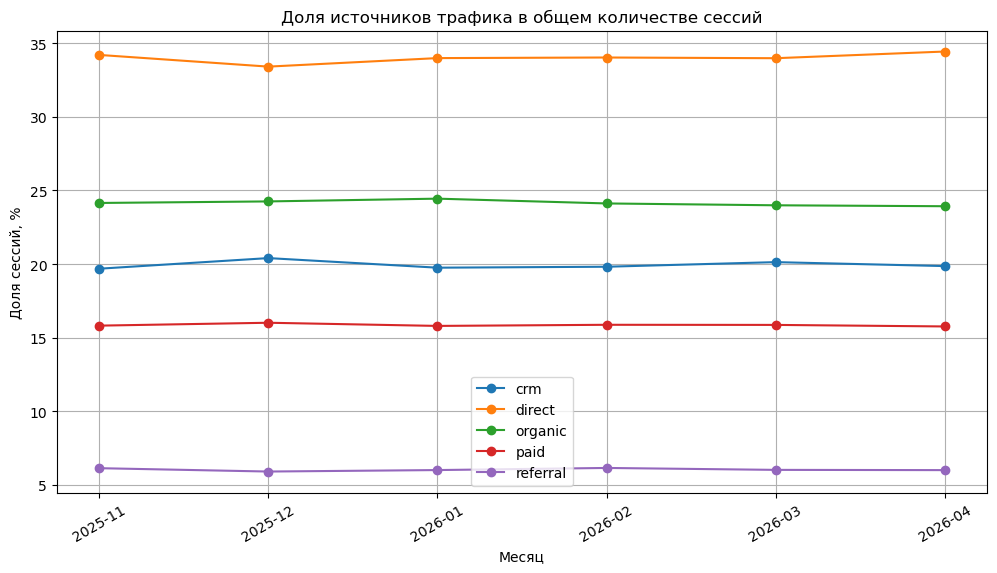

In [60]:
traffic_share = traffic_monthly.copy()

# общий объем сессий в каждом месяце
traffic_share['total_sessions_month'] = (
    traffic_share
    .groupby('month')['sessions']
    .transform('sum')
)

# доля источника трафика в сессиях месяца
traffic_share['sessions_share'] = (
    traffic_share['sessions']
    / traffic_share['total_sessions_month']
    * 100
)

plt.figure(figsize=(12, 6))

for source in traffic_share['traffic_source'].dropna().unique():

    data = traffic_share[
        traffic_share['traffic_source'] == source
    ]

    plt.plot(
        data['month'],
        data['sessions_share'],
        marker='o',
        label=source
    )

plt.title('Доля источников трафика в общем количестве сессий')
plt.xlabel('Месяц')
plt.ylabel('Доля сессий, %')
plt.legend()
plt.grid(True)
plt.xticks(rotation=30)
plt.show()

### Проверка результатов на стат. значимость

**Проверим гипотезу о том, что падение GMV вызвано изменением скидок в апреле относительно марта**

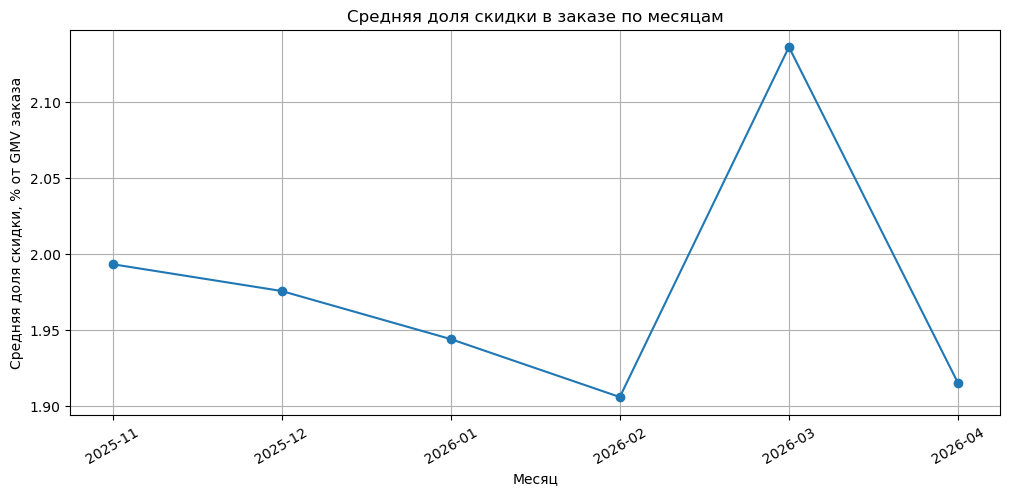

,month,count,mean,median,std
0,2025-11,3659,0.019932,0.0,0.047802
1,2025-12,3942,0.019756,0.0,0.046169
2,2026-01,3719,0.019440,0.0,0.045647
3,2026-02,3491,0.019059,0.0,0.047734
4,2026-03,3955,0.021361,0.0,0.046854
5,2026-04,3118,0.019151,0.0,0.046713


In [67]:
orders['discount_share_order'] = (
    orders['discount_amount'] / orders['paid_amount']
)

discount_month_stats = (
    orders
    .groupby('month')['discount_share_order']
    .agg(['count', 'mean', 'median', 'std'])
    .reset_index()
)

plt.figure(figsize=(12, 5))

plt.plot(
    discount_month_stats['month'],
    discount_month_stats['mean'] * 100,
    marker='o'
)

plt.title('Средняя доля скидки в заказе по месяцам')
plt.xlabel('Месяц')
plt.ylabel('Средняя доля скидки, % от GMV заказа')
plt.grid(True)
plt.xticks(rotation=30)

plt.show()

discount_month_stats

In [62]:
from scipy import stats
from statsmodels.stats.multicomp import pairwise_tukeyhsd

months = sorted(orders['month'].unique())

groups = [
    orders.loc[orders['month'] == month, 'discount_share_order'].dropna()
    for month in months
]

f_stat, p_value = stats.f_oneway(*groups)

print('ANOVA')
print(f'F-statistic: {f_stat:.4f}')
print(f'p-value: {p_value:.4f}')

ANOVA
F-statistic: 1.2245
p-value: 0.2945


In [63]:
tukey = pairwise_tukeyhsd(
    endog=orders['discount_share_order'],
    groups=orders['month'],
    alpha=0.05
)

print(tukey)

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
 group1  group2 meandiff p-adj   lower  upper  reject
-----------------------------------------------------
2025-11 2025-12  -0.0002    1.0 -0.0032 0.0029  False
2025-11 2026-01  -0.0005 0.9976 -0.0036 0.0026  False
2025-11 2026-02  -0.0009 0.9695  -0.004 0.0023  False
2025-11 2026-03   0.0014 0.7679 -0.0016 0.0045  False
2025-11 2026-04  -0.0008 0.9837  -0.004 0.0025  False
2025-12 2026-01  -0.0003 0.9997 -0.0034 0.0027  False
2025-12 2026-02  -0.0007 0.9879 -0.0038 0.0024  False
2025-12 2026-03   0.0016 0.6489 -0.0014 0.0046  False
2025-12 2026-04  -0.0006 0.9945 -0.0038 0.0026  False
2026-01 2026-02  -0.0004 0.9994 -0.0035 0.0028  False
2026-01 2026-03   0.0019 0.4675 -0.0011  0.005  False
2026-01 2026-04  -0.0003 0.9999 -0.0035  0.003  False
2026-02 2026-03   0.0023 0.2776 -0.0008 0.0054  False
2026-02 2026-04   0.0001    1.0 -0.0032 0.0034  False
2026-03 2026-04  -0.0022 0.3587 -0.0054  0.001  False
----------------------------

По результатам однофакторного ANOVA p-value > 0.05. Следовательно, нет оснований отвергнуть нулевую гипотезу о равенстве средних долей скидки между месяцами.

Это означает, что апрель статистически значимо не отличается от всех остальных месяцев по средней доле скидки в заказе. 

**Проверка значимости падения конверсий**

Для проверки значимости изменения конверсий между мартом и апрелем был применен z-test для двух долей. Для каждого этапа воронки сравнивалась доля пользователей, перешедших на следующий этап, среди пользователей, достигших предыдущего этапа.

Дополнительно была применена поправка Холма на множественные проверки, так как одновременно тестировалось несколько этапов воронки.

In [64]:
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests

prev_month = '2026-03'
last_month = '2026-04'

conversion_steps = [
    {
        'step': 'visit_to_search_cr',
        'step_name': 'Сессия → Поиск',
        'success_col': 'product_search',
        'base_col': 'service_visit'
    },
    {
        'step': 'search_to_card_cr',
        'step_name': 'Поиск → Карточка',
        'success_col': 'product_card_view',
        'base_col': 'product_search'
    },
    {
        'step': 'card_to_cart_cr',
        'step_name': 'Карточка → Добавление в корзину',
        'success_col': 'add_to_cart',
        'base_col': 'product_card_view'
    },
    {
        'step': 'cart_add_to_cart_visit_cr',
        'step_name': 'Добавление в корзину → Переход в корзину',
        'success_col': 'cart_visit',
        'base_col': 'add_to_cart'
    },
    {
        'step': 'cart_to_purchase_cr',
        'step_name': 'Корзина → Покупка',
        'success_col': 'purchase',
        'base_col': 'cart_visit'
    },
    {
        'step': 'session_to_purchase_cr',
        'step_name': 'Сессия → Покупка',
        'success_col': 'purchase',
        'base_col': 'service_visit'
    }
]

tests = []

for step in conversion_steps:
    
    success_col = step['success_col']
    base_col = step['base_col']

    april_success = funnel.loc[
        funnel['month'] == last_month,
        success_col
    ].sum()

    march_success = funnel.loc[
        funnel['month'] == prev_month,
        success_col
    ].sum()

    april_base = funnel.loc[
        funnel['month'] == last_month,
        base_col
    ].sum()

    march_base = funnel.loc[
        funnel['month'] == prev_month,
        base_col
    ].sum()

    count = np.array([april_success, march_success])
    nobs = np.array([april_base, march_base])

    stat, p_value = proportions_ztest(count, nobs)

    april_rate = april_success / april_base
    march_rate = march_success / march_base

    tests.append({
        'step': step['step'],
        'step_name': step['step_name'],
        'april_success': april_success,
        'april_base': april_base,
        'march_success': march_success,
        'march_base': march_base,
        'april_cr_%': april_rate * 100,
        'march_cr_%': march_rate * 100,
        'diff_pp': (april_rate - march_rate) * 100,
        'relative_change_%': (april_rate / march_rate - 1) * 100,
        'z_stat': stat,
        'p_value': p_value
    })

conversion_tests = pd.DataFrame(tests)

# Поправка на множественные проверки
conversion_tests['p_value_adj'] = multipletests(
    conversion_tests['p_value'],
    method='holm'
)[1]

conversion_tests['is_significant_5%'] = (
    conversion_tests['p_value_adj'] < 0.05
)

conversion_tests = conversion_tests.sort_values('diff_pp')

display(conversion_tests.round(4))

,step,step_name,april_success,april_base,march_success,march_base,april_cr_%,march_cr_%,diff_pp,relative_change_%,z_stat,p_value,p_value_adj,is_significant_5%
2,card_to_cart_cr,Карточка → Добавление в корзину,6460,13815,7916,14972,46.7608,52.8720,-6.1113,-11.5586,-10.3604,0.0000,0.0000,True
5,session_to_purchase_cr,Сессия → Покупка,3118,23233,3955,25014,13.4206,15.8111,-2.3906,-15.1196,-7.4177,0.0000,0.0000,True
4,cart_to_purchase_cr,Корзина → Покупка,3118,5048,3955,6249,61.7670,63.2901,-1.5231,-2.4065,-1.6634,0.0962,0.3849,False
3,cart_add_to_cart_visit_cr,Добавление в корзину → Переход в корзину,5048,6460,6249,7916,78.1424,78.9414,-0.7990,-1.0121,-1.1615,0.2454,0.4908,False
0,visit_to_search_cr,Сессия → Поиск,16604,23233,18021,25014,71.4673,72.0437,-0.5763,-0.8000,-1.4052,0.1600,0.4799,False
1,search_to_card_cr,Поиск → Карточка,13815,16604,14972,18021,83.2028,83.0809,0.1220,0.1468,0.3029,0.7620,0.7620,False


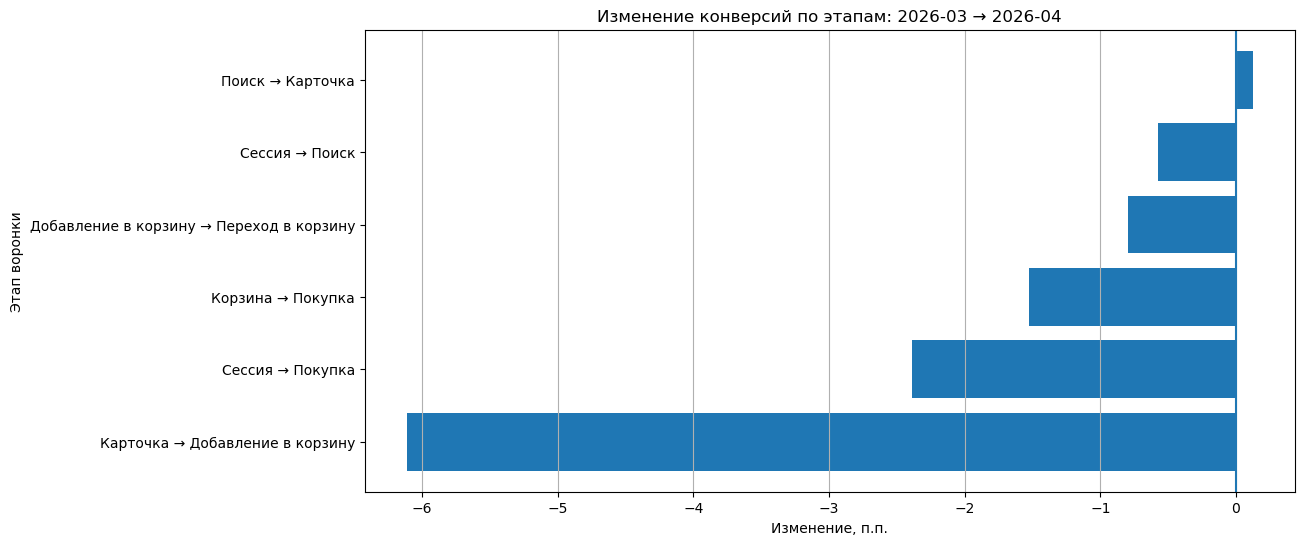

In [66]:
plt.figure(figsize=(12, 6))

plt.barh(
    conversion_tests['step_name'],
    conversion_tests['diff_pp']
)

plt.axvline(0)

plt.title(f'Изменение конверсий по этапам: {prev_month} → {last_month}')
plt.xlabel('Изменение, п.п.')
plt.ylabel('Этап воронки')
plt.grid(axis='x')

plt.show()

Результаты теста показывают, что наиболее сильное и статистически значимое снижение наблюдается на этапе «Карточка → Добавление в корзину». Это подтверждает вывод, полученный на графиках: основная просадка возникает в момент принятия решения о добавлении товара в корзину.

Также статистически значимо снижается итоговая конверсия «Сессия → Покупка», что подтверждает, что падение заказов в апреле не является случайным.

## Выводы и рекомендации

## Выводы

В апреле наблюдается существенное снижение ключевой бизнес-метрики GMV: оборот снизился на 24.2% относительно марта.

Декомпозиция GMV показала, что основной вклад в падение внесло снижение количества заказов. Количество заказов сократилось на 21.2%, тогда как средний чек снизился только на 3.9%. Следовательно, падение оборота связано преимущественно не с размером заказа, а с уменьшением числа покупок.

Дополнительно было выявлено, что количество сессий снизилось только на 7.1%, тогда как количество заказов упало значительно сильнее. Это означает, что падение заказов нельзя объяснить только снижением трафика: важным фактором стало ухудшение конверсии пользователей в покупку.

Анализ воронки показал, что наиболее проблемным этапом является переход от просмотра карточки товара к добавлению товара в корзину. Конверсия на этом этапе снизилась с 52.9% в марте до 46.8% в апреле, то есть на 6.1 п.п. Z-test для двух долей подтвердил, что это снижение статистически значимо. Также статистически значимо снизилась итоговая конверсия из сессии в покупку.

Это говорит о том, что пользователи продолжают заходить в сервис, искать товары и просматривать карточки, но в апреле стали заметно реже добавлять товары в корзину. Проблема возникает не на верхнем уровне воронки, а в момент принятия решения о покупке.

Анализ срезов показал, что падение GMV наблюдается практически во всех ключевых сегментах: по платформам, городам, типам скидок, маркетинговому касанию и способам оплаты. Это означает, что проблема не является локальной для одной платформы, города или платежного метода, а носит системный характер.

При этом отдельные сегменты просели сильнее остальных:
- среди платформ сильнее всего снизился Web;
- среди городов наиболее сильное падение наблюдается в Новосибирске и Казани;
- среди типов скидок сильнее всего просели заказы с промо-механиками: free_delivery, fixed_amount и percent;
- маркетинговые заказы снизились немного сильнее немаркетинговых.

Отдельно была проверена гипотеза о влиянии скидочной механики. В марте доля скидок в GMV была выше, а в апреле снизилась до уровня, близкого к предыдущим месяцам. Это может указывать на то, что в марте действовала более сильная промоактивность, которая поддерживала спрос и конверсию, а в апреле этот эффект исчез.

Однако статистический тест ANOVA не подтвердил значимого отличия апреля от остальных месяцев по средней доле скидки в заказе.

## Рекомендации

1. Приоритетно рассмотреть шаг карточка товара → добавление в корзину. Проверить изменения интерфейса карточки, доступность кнопки добавления, ошибки API, изменения в ассортименте, остатках и ценах.
2. Проверить технические метрики апреля: ошибки добавления в корзину, latency карточки товара, ошибки получения остатков, недоступность магазинов или слотов доставки.
3. Разобрать проблемные сегменты: Казань, Новосибирск и Web. В них падение конверсии особенно заметно.
4. Проверить ассортимент и наличие товаров: если товары просматривают, но не добавляют, возможны out-of-stock, плохие цены, недоступные слоты или изменения минимальной суммы заказа.
5. Сравнить изменения в продукте/релизах между мартом и апрелем: особенно в зоне карточки товара и корзины.
6. Мониторинг: добавить алерт на недельную/дневную конверсию `product_card_view → add_to_cart`, так как именно этот участок первым сигнализирует о текущей проблеме.